# Machine Learning aplicado a la predicción de cancelaciones hoteleras

## Resumen

El objetivo de este proyecto es desarrollar un modelo de Machine Learning capaz de predecir la cancelación de reservas hoteleras a partir del dataset **hotel_bookings.csv**. A través de un análisis exploratorio de los datos, su posterior limpieza y la aplicación de distintos algoritmos de clasificación, se busca identificar patrones de comportamiento en los clientes y determinar qué factores influyen en la cancelación. Este enfoque permitirá mejorar la toma de decisiones en el sector hotelero.

#### Esquema de las variables

- **hotel**: Tipo de hotel (resort o city)
- **is_canceled**: Si la reserva fue cancelada (1 sí, 0 no)
- **lead_time**: Días entre reserva y llegada
- **arrival_date_year**: Año de llegada
- **arrival_date_month**: Mes de llegada
- **arrival_date_week_number**: Semana del año
- **arrival_date_day_of_month**: Día del mes
- **stays_in_weekend_nights**: Noches en fin de semana
- **stays_in_week_nights**: Noches entre semana
- **adults**: Número de adultos
- **children**: Número de niños
- **babies**: Número de bebés
- **meal**: Tipo de pensión
    - Undefined/SC – no meal package
    - BB – Bed & Breakfast
    - HB – Half board (breakfast and one other meal – usually dinner)
    - FB – Full board (breakfast, lunch and dinner)
- **country**: País del cliente (Representado en ISO)
- **market_segment**: Segmento de mercado
    - “TA” - “Travel Agents” 
    - “TO” - “Tour Operators”
- **distribution_channel**: Canal de reserva
    - “TA” - “Travel Agents” 
    - “TO” - “Tour Operators”
- **is_repeated_guest**: Cliente repetido (1 sí, 0 no)
- **previous_cancellations**: Cancelaciones previas
- **previous_bookings_not_canceled**: Reservas previas no canceladas
- **reserved_room_type**: Tipo de habitación reservada (por proteccion se utiliza ID)
- **assigned_room_type**: Tipo de habitación asignada (por proteccion se utiliza ID)
- **booking_changes**: Cambios en la reserva
- **deposit_type**: Tipo de depósito
    - No Deposit – no deposit was made
    - Non Refund – a deposit was made in the value of the total stay cost
    - Refundable – a deposit was made with a value under the total cost of stay.
- **agent**: ID del agente que hizo la reserva
- **company**: ID de la empresa/entidad que hizo la reserva
- **days_in_waiting_list**: Días en lista de espera
- **customer_type**: Tipo de cliente
    - Contract - when the booking has an allotment or other type of contract associated to it
    - Group – when the booking is associated to a group
    - Transient – when the booking is not part of a group or contract, and is not associated to other transient booking
    - Transient-party – when the booking is transient, but is associated to at least other transient booking
- **adr**: Precio medio diario de la reserva. Se calcula dividiendo el ingreso total generado por la reserva entre el número total de noches de estancia. Indica cuánto paga, de media, un cliente por noche.
- **required_car_parking_spaces**: Plazas de parking requeridas
- **total_of_special_requests**: Número de peticiones especiales
- **reservation_status**: Estado último de la reserva
  - Canceled – booking was canceled by the customer
  - Check-Out – customer has checked in but already departed
  - No-Show – customer did not check-in and did inform the hotel of the reason why
- **reservation_status_date**: Fecha del estado último

# 1. Análisis Exploratorio de Datos (EDA)

En esta fase inicial del proyecto se realiza un Análisis Exploratorio de Datos (EDA) con el objetivo de comprender la estructura del dataset **hotel_bookings.csv** y obtener una visión general de las variables disponibles.

El EDA permite identificar patrones iniciales en los datos, detectar posibles problemas y preparar la información. En concreto, en esta etapa se llevarán a cabo las siguientes tareas:

- Análisis de la estructura del dataset: número de observaciones, variables y tipos de datos.
- Estudio de valores nulos e inconsistencia
- Estadisticos descriptivos en variables numéricas.
- Estudio de variables categóricas
- Análisis de la variable objetivo (**cancelación de reservas**).
- Exploración de relaciones entre variables mediante correlaciones.

Este análisis es fundamental para garantizar la calidad de los datos.

### Importamos la base de datos y librerias

In [57]:
# Importar librerías básicas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings("ignore")

In [20]:
# Cargar dataset
df = pd.read_csv("hotel_bookings.csv")
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


### 1.1 Análisis de la estructura del dataset: número de observaciones, variables y tipos de datos

In [3]:
# Dimensiones del dataset
print("Número de observaciones y variables:", df.shape)

# Tipos de datos
print("\nTipos de datos:")
print(df.dtypes)

# Información general
print("\nInformación general del dataset:")
df.info()

Número de observaciones y variables: (119390, 32)

Tipos de datos:
hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                                  str
country                               str
market_segment                        str
distribution_channel                  str
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                    str
assigned_room_type                    str
booking_changes                     int64
deposit_t

El dataset analizado contiene **119.390 observaciones y 32 variables**, lo que indica un volumen de datos suficientemente grande para aplicar técnicas de Machine Learning con buena capacidad de generalización.

En cuanto a los tipos de variables:
- Se observan variables **numéricas (int64 y float64)**, principalmente relacionadas con características de la reserva (lead_time, número de noches, ADR, etc.).
- También existen múltiples variables **categóricas (object)** como el tipo de hotel, país, segmento de mercado o tipo de cliente, que serán relevantes en el análisis pero requerirán transformación posterior para su uso en modelos.

Por último, la variable objetivo `is_canceled` está correctamente definida como variable binaria (0 = no cancelada, 1 = cancelada), lo que confirma que el problema a abordar es de **clasificación supervisada**.

### 1.2 Estudio de valores nulos e inconsistencia

In [4]:
# Contar valores nulos por columna
null_values = df.isnull().sum()

# Mostrar solo columnas con valores nulos
null_values = null_values[null_values > 0].sort_values(ascending=False)
print(null_values)

company     112593
agent        16340
country        488
children         4
dtype: int64


In [6]:
#Analizamos ahora, valores inconsistentes como una reserva sin ningun huespeded o reservas de bebes y niños sin adultos
total = len(df)

# 1. Reservas sin huéspedes
no_guests = df[(df["adults"] == 0) & (df["children"].fillna(0) == 0) & (df["babies"] == 0)]
print(f"Reservas sin huéspedes: {no_guests.shape[0]} ({round(no_guests.shape[0]/total*100, 4)}%)")

# 2. Niños o bebés sin adultos
no_adults = df[(df["adults"] == 0) & ((df["children"].fillna(0) > 0) | (df["babies"] > 0))]
print(f"Reservas con niños/bebés pero sin adultos: {no_adults.shape[0]} ({round(no_adults.shape[0]/total*100, 4)}%)")

# 3. Estancias con noches = 0
no_nights = df[(df["stays_in_weekend_nights"] == 0) & (df["stays_in_week_nights"] == 0)]
print(f"Reservas sin noches: {no_nights.shape[0]} ({round(no_nights.shape[0]/total*100, 4)}%)")

# 4. ADR negativo
negative_adr = df[df["adr"] < 0]
print(f"Reservas con ADR negativo: {negative_adr.shape[0]} ({round(negative_adr.shape[0]/total*100, 4)}%)")

Reservas sin huéspedes: 180 (0.1508%)
Reservas con niños/bebés pero sin adultos: 223 (0.1868%)
Reservas sin noches: 715 (0.5989%)
Reservas con ADR negativo: 1 (0.0008%)


In [7]:
# Estudiamos, qué porcentaje de datos quitamos, si eliminamos los valores nulos y las inconsistencias, no tenemos en cuenta los valores nulos de agent

mask_country_null = df["country"].isnull()
mask_children_null = df["children"].isnull()
mask_no_guests = (df["adults"] == 0) & (df["children"].fillna(0) == 0) & (df["babies"] == 0)
mask_no_adults = (df["adults"] == 0) & ((df["children"].fillna(0) > 0) | (df["babies"] > 0))
mask_no_nights = (df["stays_in_weekend_nights"] == 0) & (df["stays_in_week_nights"] == 0)
mask_negative_adr = df["adr"] < 0

# Unión de todas las condiciones
mask_remove = (
    mask_country_null
    | mask_children_null
    | mask_no_guests
    | mask_no_adults
    | mask_no_nights
    | mask_negative_adr
)

# Filas totales a eliminar sin contar duplicadas
rows_to_remove = df[mask_remove]

print("Número total de filas a eliminar:", rows_to_remove.shape[0])
print("Porcentaje total respecto al dataset:", round(rows_to_remove.shape[0] / total * 100, 4), "%")

Número total de filas a eliminar: 1526
Porcentaje total respecto al dataset: 1.2782 %


En el análisis de calidad de los datos se han detectado valores nulos en varias variables:

- `company`: 112.593 valores nulos → **se eliminará la variable**, l tratarse de un identificador sin valor predictivo directo.
- `agent`: 16.340 valores nulos → **se eliminará la variable**, al tratarse de un identificador sin valor predictivo directo.
- `country`: 488 valores nulos (~0.41%) → **se eliminarán las filas**, ya que el impacto es muy reducido.
- `children`: 4 valores nulos (~0.003%) → **se eliminarán las filas**, impacto prácticamente nulo.

Además, se han identificado varias **inconsistencias en los datos**:

- Reservas sin huéspedes: 180 (0.1508%)
- Reservas con niños/bebés pero sin adultos: 223 (0.1868%)
- Reservas sin noches: 715 (0.5989%)
- Reservas con ADR negativo: 1 (0.0008%)

Considerando todas estas incidencias de forma conjunta (evitando duplicidades), se eliminarán:

- **1.526 filas en total**, lo que supone aproximadamente un **1.2782% del dataset**.

Dado que este porcentaje es muy bajo, la eliminación de estas observaciones **no afectará significativamente a la representatividad de los datos**, permitiendo trabajar con un dataset más limpio y consistente para el modelado.

### 1.3 Estadisticos descriptivos en variables numéricas

In [8]:
# Estadísticos descriptivos de variables numéricas
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


#### Normalización de variables y detección de outliers

En este proyecto se aplicará normalización a las variables numéricas, manteniendo sin transformar las variables binarias.

La normalización consiste en escalar las variables para que tengan una distribución comparable (por ejemplo, media 0 y desviación típica 1 en el caso de la estandarización). Este proceso es necesario por los siguientes motivos:

- Las variables del dataset presentan **escalas muy diferentes**:
  - `lead_time` puede alcanzar valores de hasta 737 días.
  - `adr` presenta valores muy elevados (hasta 5400).
  - `days_in_waiting_list` llega hasta 391.
  - Otras variables como `babies` o `children` tienen valores muy pequeños.

- Los algoritmos de Machine Learning basados en distancias (como **KNN**) o en optimización (como **Regresión Logística**) son sensibles a la escala de las variables. Si no se normalizan, las variables con valores más altos dominarían el modelo.

- La normalización mejora la **convergencia de los modelos**, la estabilidad numérica y la interpretabilidad de los coeficientes.

Por otro lado, **no se normalizan las variables binarias** (como `is_canceled` o `is_repeated_guest`) porque:
- Ya están en una escala homogénea (0 y 1).
- No aportaría información adicional transformarlas.

A partir del análisis descriptivo, se identifican variables con alta dispersión o valores extremos que pueden influir negativamente en el modelo. Para ello, se analiza en detalle las siguientes variables:

- **lead_time**
  - Presenta un rango muy amplio (0 a 737 días).
  - Pero tiene utilidad para saber si se hace la reserva con mucha antelacion si afecta a nuestra variable objetivo
 
- **days_in_waiting_list**
  - Valores muy dispersos, con máximos elevados (hasta 391 días), aunque posibles en el mundo de la hosteleria.

- **adr**
  - Se observan valores extremadamente altos (hasta 5400).
  - También se detectan valores negativos, lo cual es inconsistente.

- **stays_in_week_nights** y **stays_in_weekend_nights**
  - Máximos elevados (hasta 50 noches), lo que puede indicar outliers, aunque también son psoibles las estancias largas en hoteles.


El uso de boxplots permitirá identificar visualmente estos valores y tomar decisiones fundamentadas en la fase de preprocesamiento.

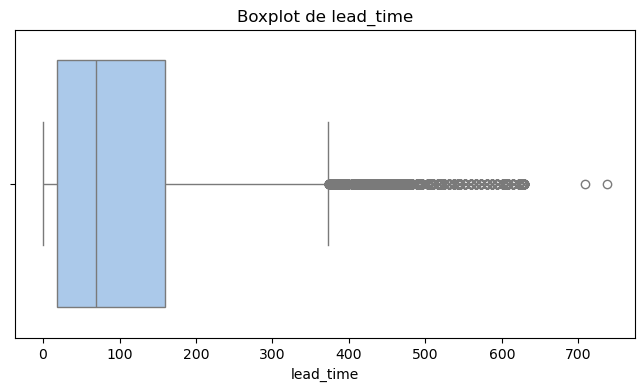

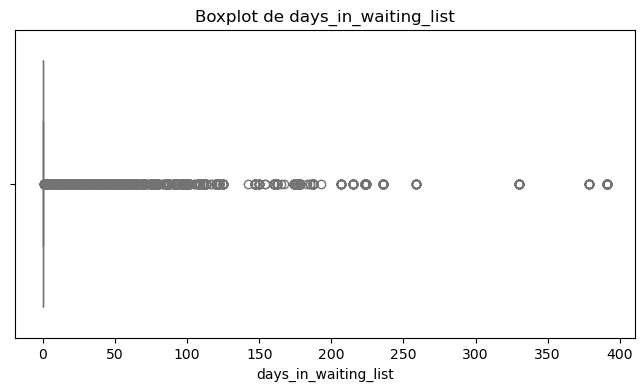

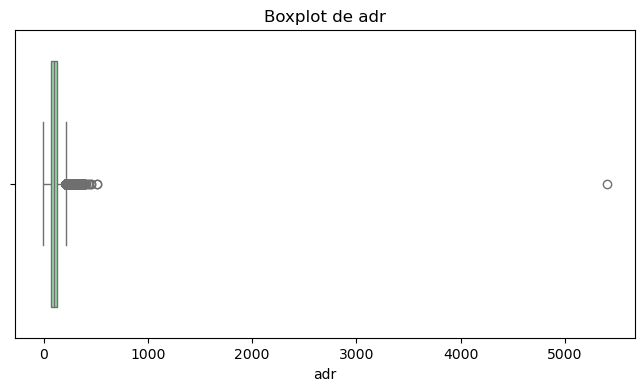

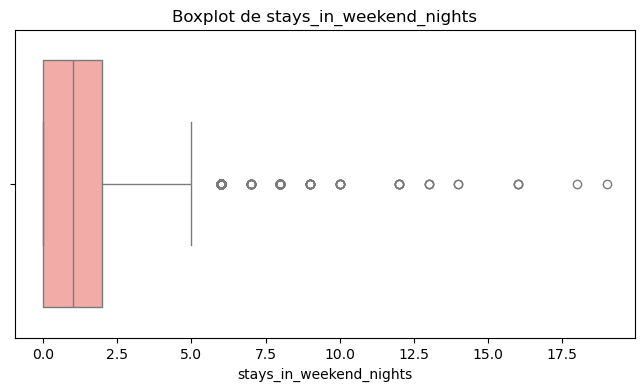

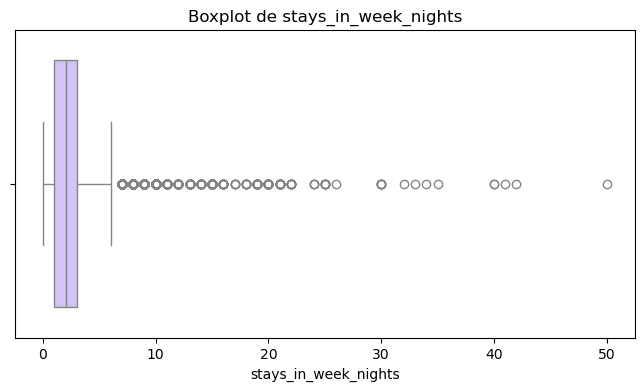

In [9]:
# Boxplots para detectar outliers
pastel_colors = sns.color_palette("pastel", 5)

for i, col in enumerate(["lead_time", "days_in_waiting_list", "adr", "stays_in_weekend_nights", "stays_in_week_nights"]):
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col], color=pastel_colors[i])
    plt.title(f"Boxplot de {col}")
    plt.show()

Tras el análisis mediante boxplots, se observa la presencia de valores extremos en varias variables. Sin embargo, no todos los outliers deben ser eliminados.

En la mayoría de las variables (como `lead_time`, `days_in_waiting_list`, `stays_in_weekend_nights`o`stays_in_week_nights`), los valores extremos representan comportamientos reales del negocio (reservas con mucha antelación, estancias largas, etc.), por lo que se decide **no eliminarlos** para no perder información relevante.

No obstante, en la variable `adr` se detecta un valor extremadamente alto (superior a 5000), claramente alejado del comportamiento habitual de los datos.

Por ello, se decide:
- Eliminar valores negativos de `adr` (inconsistentes)
- Eliminar valores extremadamente altos (`adr > 5000`)

Este enfoque permite mantener la información relevante del dataset, evitando al mismo tiempo que valores anómalos distorsionen el modelo.

### 1.4 Estudio de variables categóricas

In [58]:
# Revisar valores únicos en variables categóricas
categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    print(f"\nColumna: {col}")
    print(df[col].value_counts().head(10))


Columna: hotel
hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64

Columna: arrival_date_month
arrival_date_month
August       13877
July         12661
May          11791
October      11160
April        11089
June         10939
September    10508
March         9794
February      8068
November      6794
Name: count, dtype: int64

Columna: meal
meal
BB           92310
HB           14463
SC           10650
Undefined     1169
FB             798
Name: count, dtype: int64

Columna: country
country
PRT    48590
GBR    12129
FRA    10415
ESP     8568
DEU     7287
ITA     3766
IRL     3375
BEL     2342
BRA     2224
NLD     2104
Name: count, dtype: int64

Columna: market_segment
market_segment
Online TA        56477
Offline TA/TO    24219
Groups           19811
Direct           12606
Corporate         5295
Complementary      743
Aviation           237
Undefined            2
Name: count, dtype: int64

Columna: distribution_channel
distribution_channel
TA/TO        97870


Durante el análisis de las variables categóricas se observa que muchas de ellas presentan un elevado número de categorías, lo que puede generar un aumento significativo en la dimensionalidad del dataset tras aplicar técnicas como One-Hot Encoding.

Esto puede provocar:
- Mayor complejidad en el modelo
- Riesgo de sobreajuste
- Aumento del ruido en los datos

Por ello, se han tomado las siguientes decisiones:

1. Se considera relevante crear una nueva variable:

- **room_changed**: indica si la habitación reservada es distinta de la asignada.

Esta variable se define como:

- 1 → si `reserved_room_type` ≠ `assigned_room_type`
- 0 → si son iguales

La creación de esta variable permite capturar información relevante sobre posibles cambios en la reserva, que pueden estar relacionados con la satisfacción del cliente y la probabilidad de cancelación.

Además, permite reducir la complejidad del modelo al sustituir dos variables categóricas por una variable binaria.

2. Se considera relevante agrupar: 
- **country**:
  - Presenta un elevado número de categorías.
  - Se agruparán los países menos frecuentes en una categoría "Other" para reducir dimensionalidad (ITA, IRL ,BEL , BRA, NLD...)-

3. Se considera relevante eliminar las siguientes variables porque pueden causar overfitting en el modelo:

- **reservation_status**
- **reservation_status_date**

### 1.5 Análisis de la variable objetivo (**cancelación de reservas**)

In [6]:
# Distribución de la variable objetivo
print(df["is_canceled"].value_counts())
print(df["is_canceled"].value_counts(normalize=True) * 100)

is_canceled
0    75166
1    44224
Name: count, dtype: int64
is_canceled
0    62.958372
1    37.041628
Name: proportion, dtype: float64


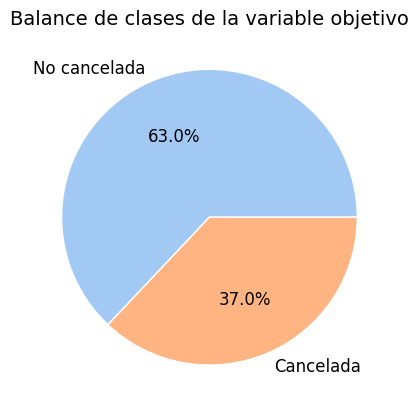

In [7]:
# Gráfico circular del balance de clases
colors = sns.color_palette("pastel")

df["is_canceled"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    labels=["No cancelada", "Cancelada"],
    colors=colors,
    wedgeprops={"edgecolor": "white"},
    textprops={"fontsize": 12}
)

plt.title("Balance de clases de la variable objetivo", fontsize=14)
plt.ylabel("")
plt.show()

La variable objetivo del modelo es **`is_canceled`**, que indica si una reserva ha sido cancelada o no:

- 0 → Reserva no cancelada  
- 1 → Reserva cancelada  

Se observa la siguiente distribución:

- **Reservas no canceladas (0)**: 75.166 → **62.96%**
- **Reservas canceladas (1)**: 44.224 → **37.04%**

La variable objetivo presenta un cierto **desbalanceo de clases**, aunque no es extremo. Existe una mayor proporción de reservas no canceladas frente a canceladas.

### 1.6 Exploración de relaciones entre variables mediante correlaciones

In [8]:
# Matriz de correlación
corr_matrix = df.select_dtypes(include=np.number).corr()

 
#Correlación con la variable objetivo
corr_with_target = corr_matrix["is_canceled"].sort_values(ascending=False)
print(corr_with_target)

is_canceled                       1.000000
lead_time                         0.293123
previous_cancellations            0.110133
adults                            0.060017
days_in_waiting_list              0.054186
adr                               0.047557
stays_in_week_nights              0.024765
arrival_date_year                 0.016660
arrival_date_week_number          0.008148
children                          0.005048
stays_in_weekend_nights          -0.001791
arrival_date_day_of_month        -0.006130
company                          -0.020642
babies                           -0.032491
previous_bookings_not_canceled   -0.057358
agent                            -0.083114
is_repeated_guest                -0.084793
booking_changes                  -0.144381
required_car_parking_spaces      -0.195498
total_of_special_requests        -0.234658
Name: is_canceled, dtype: float64


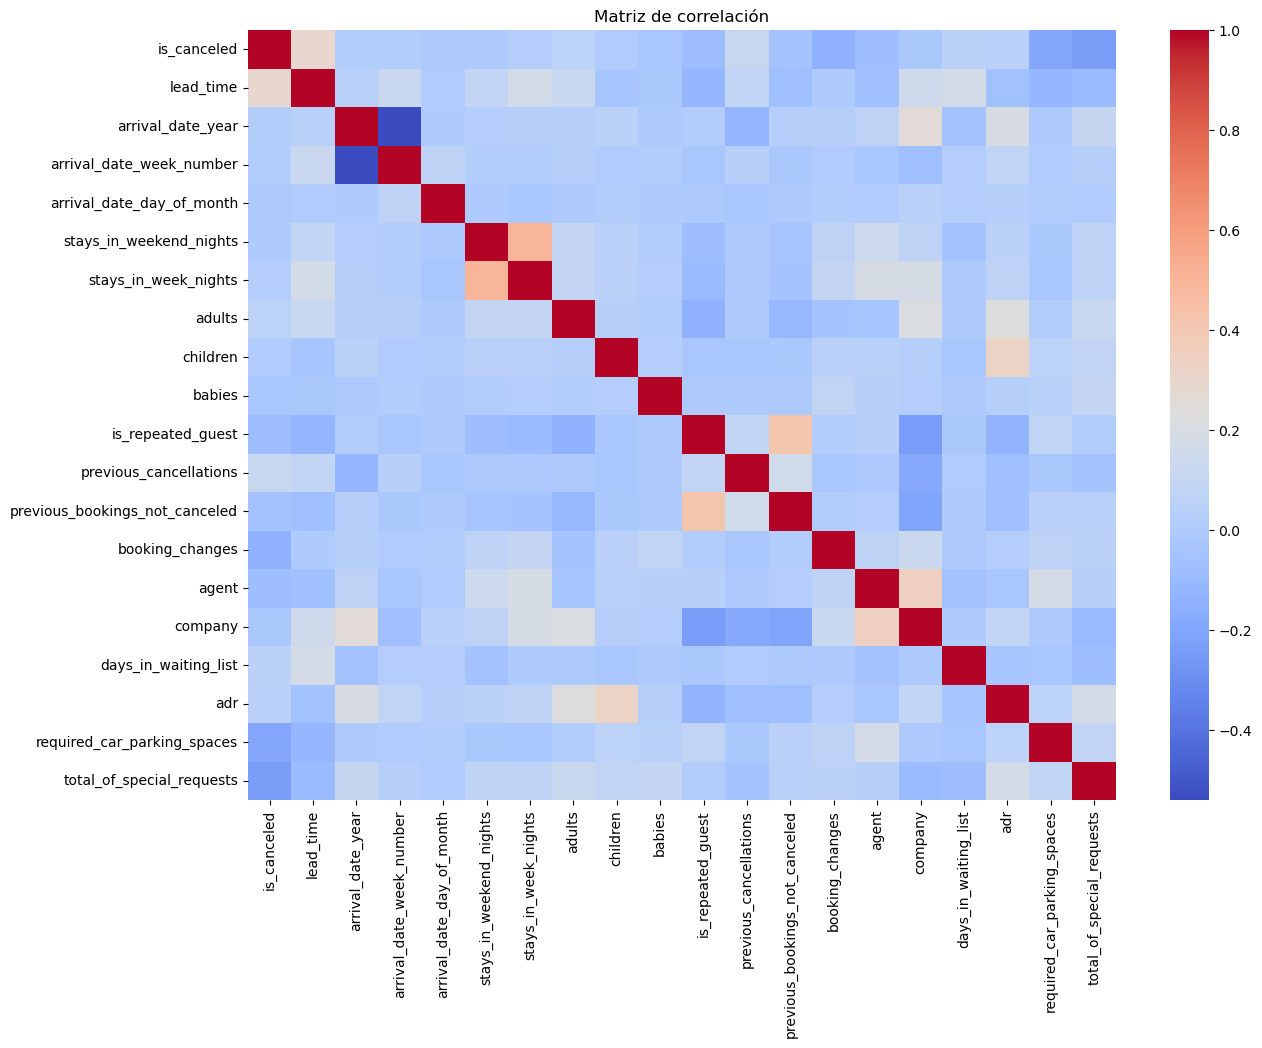

In [14]:
# Matriz de correlación
corr_matrix = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, cmap="coolwarm", annot=False)
plt.title("Matriz de correlación")
plt.show()

Las variables que presentan mayor relación con la cancelación (`is_canceled`) son:

- **lead_time (0.29)**  
  → Es la variable más relevante. Cuanto mayor es el tiempo entre la reserva y la llegada, mayor es la probabilidad de cancelación.

- **previous_cancellations (0.11)**  
  → Clientes con historial de cancelaciones tienen mayor probabilidad de cancelar de nuevo.

- **adults (0.06)** y **days_in_waiting_list (0.05)**  
  → Relación positiva débil.

- **adr (0.047)**  
  → Ligera relación positiva: precios más altos podrían asociarse a mayor probabilidad de cancelación.

Por otro lado, las variables con correlación negativa más destacadas son:

- **total_of_special_requests (-0.23)**  
  → A mayor número de peticiones especiales, menor probabilidad de cancelación (clientes más comprometidos).

- **required_car_parking_spaces (-0.20)**  
  → Clientes que solicitan parking tienen menor probabilidad de cancelar.

- **booking_changes (-0.14)**  
  → Más cambios en la reserva pueden indicar mayor intención de mantenerla.

- **is_repeated_guest (-0.08)**  
  → Clientes recurrentes cancelan menos.

Se observan algunas correlaciones entre variables explicativas:

- **stays_in_week_nights** y **stays_in_weekend_nights** presentan cierta correlación positiva, ya que ambas reflejan la duración de la estancia.

- **previous_cancellations** y **previous_bookings_not_canceled** muestran cierta relación, al estar ambas vinculadas al historial del cliente.

En general, no se detectan **correlaciones muy altas entre variables independientes**, lo que reduce el riesgo de multicolinealidad.

- Este análisis solo incluye **variables numéricas**, ya que las variables categóricas no pueden analizarse directamente mediante correlación de Pearson. Estas serán tratadas posteriormente mediante técnicas de codificación (encoding).


# 2. Limpieza y preparacion de los datos 

In [21]:
# 1. COPIA DEL DATASET ORIGINAL

df_clean = df.copy()

# 2. ELIMINAR VARIABLES NO RELEVANTES O CON MUCHOS NULOS
# Se eliminan 'company' y 'agent' por ser identificadores y no aportar valor predictivo directo.

df_clean = df_clean.drop(columns=["company", "agent"])
df_clean = df_clean.dropna()

# 4. ELIMINAR INCONSISTENCIAS DETECTADAS
# Se eliminan:
# - reservas sin huéspedes
# - reservas con niños/bebés pero sin adultos
# - reservas sin noches
# - reservas con ADR negativo

df_clean = df_clean[
    ~(
        ((df_clean["adults"] == 0) & (df_clean["children"] == 0) & (df_clean["babies"] == 0)) |
        ((df_clean["adults"] == 0) & ((df_clean["children"] > 0) | (df_clean["babies"] > 0))) |
        ((df_clean["stays_in_weekend_nights"] == 0) & (df_clean["stays_in_week_nights"] == 0)) |
        (df_clean["adr"] < 0)
    )
]

# 5. ELIMINAR OUTLIER EXTREMO DE ADR
# Se elimina el valor extremadamente alto de ADR (> 5000)
# por estar claramente fuera del comportamiento habitual.

df_clean = df_clean[df_clean["adr"] <= 5000]


# 6. CREAR NUEVA VARIABLE: room_changed
# 1 si la habitación reservada es distinta de la asignada
# 0 si son iguales

df_clean["room_changed"] = (
    df_clean["reserved_room_type"] != df_clean["assigned_room_type"]
).astype(int)


# 7. ELIMINAR VARIABLES QUE PUEDEN APORTAR OVERFITTING
# - reserved_room_type y assigned_room_type se sustituyen por la variable binaria room_changed
# - reservation_status y reservation_status_date se eliminan por contener información futura (data leakage)

# - arrival_date_week_number y arrival_date_day_of_month se eliminan para reducir ruido y redundancia temporal,
#   manteniendo la información estacional principal en arrival_date_month

df_clean = df_clean.drop(columns=[
    "reserved_room_type",
    "assigned_room_type",
    "reservation_status",
    "reservation_status_date",
    "arrival_date_week_number",
    "arrival_date_day_of_month"
])

# 8. AGRUPAR CATEGORÍAS POCO FRECUENTES EN 'country'
# Se agrupan algunos países menos frecuentes en la categoría 'Other'

top_countries = df_clean["country"].value_counts().nlargest(5).index

df_clean["country"] = df_clean["country"].apply(
    lambda x: x if x in top_countries else "Other"
)

# 9. COMPROBAR EL TAMAÑO FINAL DEL DATASET LIMPIO

print("Dimensiones del dataset limpio:", df_clean.shape)
df_clean.head()

Dimensiones del dataset limpio: (117863, 25)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,...,previous_cancellations,previous_bookings_not_canceled,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,room_changed
2,Resort Hotel,0,7,2015,July,0,1,1,0.0,0,...,0,0,0,No Deposit,0,Transient,75.0,0,0,1
3,Resort Hotel,0,13,2015,July,0,1,1,0.0,0,...,0,0,0,No Deposit,0,Transient,75.0,0,0,0
4,Resort Hotel,0,14,2015,July,0,2,2,0.0,0,...,0,0,0,No Deposit,0,Transient,98.0,0,1,0
5,Resort Hotel,0,14,2015,July,0,2,2,0.0,0,...,0,0,0,No Deposit,0,Transient,98.0,0,1,0
6,Resort Hotel,0,0,2015,July,0,2,2,0.0,0,...,0,0,0,No Deposit,0,Transient,107.0,0,0,0


# 3. Training Set y Test Set

In [22]:
# SEPARAR VARIABLE OBJETIVO Y VARIABLES EXPLICATIVAS

X = df_clean.drop(columns=["is_canceled"])
y = df_clean["is_canceled"]

In [59]:
# IDENTIFICAR TIPOS DE VARIABLES

# Variables categóricas
categorical_cols = X.select_dtypes(include="object").columns.tolist()

# Variables numéricas
numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Variables binarias que NO se normalizan
binary_cols = [col for col in numeric_cols if X[col].nunique() == 2]

# Variables numéricas no binarias que SÍ se normalizan
numeric_to_scale = [col for col in numeric_cols if col not in binary_cols]

print("Variables categóricas:", categorical_cols)
print("\nVariables binarias:", binary_cols)
print("\nVariables numéricas a normalizar:", numeric_to_scale)

Variables categóricas: ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'deposit_type', 'customer_type']

Variables binarias: ['is_repeated_guest']

Variables numéricas a normalizar: ['lead_time', 'arrival_date_year', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']


In [24]:
#DIVISIÓN EN TRAIN Y TEST
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [25]:
# ONE-HOT ENCODING DE VARIABLES CATEGÓRICAS
# drop_first=True para evitar multicolinealidad innecesaria

X_train_encoded = pd.get_dummies(X_train, columns=categorical_cols, drop_first=True)
X_test_encoded = pd.get_dummies(X_test, columns=categorical_cols, drop_first=True)

# Igualar columnas entre train y test
X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join="left", axis=1, fill_value=0)

print("Dimensión X_train tras encoding:", X_train_encoded.shape)
print("Dimensión X_test tras encoding:", X_test_encoded.shape)

Dimensión X_train tras encoding: (94290, 52)
Dimensión X_test tras encoding: (23573, 52)


In [26]:
# NORMALIZACIÓN DE VARIABLES NUMÉRICAS NO BINARIAS
# Se ajusta el escalador SOLO con train y luego se aplica a test.

scaler = StandardScaler()

X_train_encoded[numeric_to_scale] = scaler.fit_transform(X_train_encoded[numeric_to_scale])
X_test_encoded[numeric_to_scale] = scaler.transform(X_test_encoded[numeric_to_scale])

In [27]:
# DATASETS FINALES LISTOS PARA MACHINE LEARNING

print("Dataset final de entrenamiento:", X_train_encoded.shape)
print("Dataset final de prueba:", X_test_encoded.shape)

X_train_encoded.head()

Dataset final de entrenamiento: (94290, 52)
Dataset final de prueba: (23573, 52)


,lead_time,arrival_date_year,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,...,market_segment_Online TA,distribution_channel_Direct,distribution_channel_GDS,distribution_channel_TA/TO,distribution_channel_Undefined,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Group,customer_type_Transient,customer_type_Transient-Party
13744,-0.371050,1.187458,0.065257,0.786876,0.229855,-0.257035,-0.080799,0,-0.102309,-0.088366,...,True,False,False,True,False,False,False,False,True,False
3525,-0.951242,-1.638311,-0.940481,0.786876,1.953631,2.299222,-0.080799,0,-0.102309,-0.088366,...,True,False,False,True,False,False,False,False,True,False
66916,0.480522,1.187458,-0.940481,0.257678,0.229855,-0.257035,-0.080799,0,-0.102309,-0.088366,...,False,False,False,True,False,True,False,False,True,False
3731,-0.240039,-1.638311,-0.940481,0.257678,0.229855,-0.257035,-0.080799,0,-0.102309,-0.088366,...,False,True,False,False,False,False,False,False,True,False
7600,-0.717294,-0.225426,-0.940481,0.257678,0.229855,-0.257035,-0.080799,0,-0.102309,-0.088366,...,True,False,False,True,False,False,False,False,True,False


# 4. Modelos 

In [28]:
# Imports necesarios
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
import numpy as np

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.inspection import PartialDependenceDisplay, permutation_importance

## 4.1 Naive Bayes

=== Confusion Matrix ===


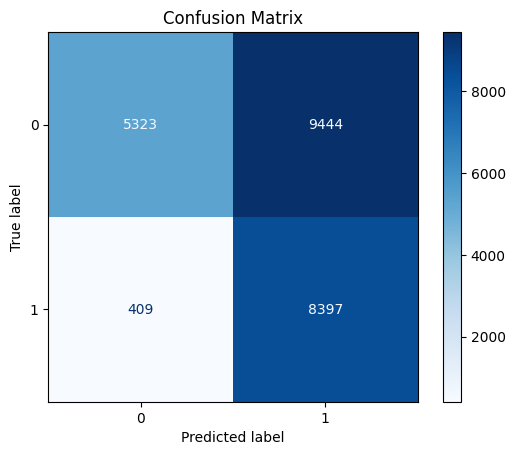


=== Main Metrics ===
Accuracy    = 0.5820
Precision   = 0.4707
Recall      = 0.9536
F1-score    = 0.6302
Specificity = 0.3605

=== ROC Curve ===
ROC-AUC     = 0.8281


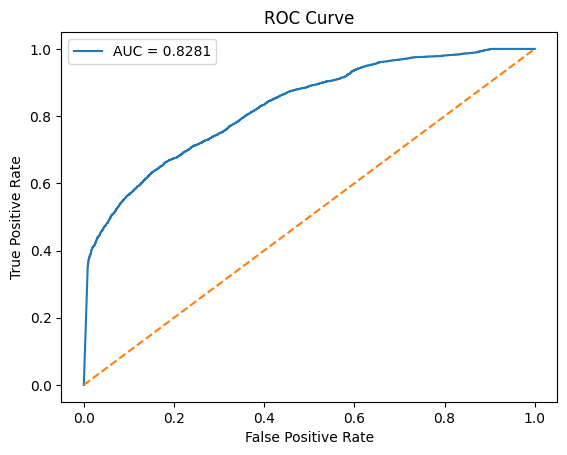

In [60]:
# Crear modelo
nb_model = GaussianNB()

# Entrenar
nb_model.fit(X_train_encoded, y_train)

# Predecir
y_pred_nb = nb_model.predict(X_test_encoded)

#CODIGO BASE DE EVALUACIÓN DE MODELOS 

if hasattr(nb_model, "predict_proba"):
    y_score = nb_model.predict_proba(X_test_encoded)[:, 1]  
elif hasattr(nb_model, "decision_function"):
    y_score = nb_model.decision_function(X_test_encoded)
else:
    y_score = None

# MARIZ DE CONFUSIÓN

cm_nb = confusion_matrix(y_test, y_pred_nb)
tn, fp, fn, tp = cm_nb.ravel()

print("=== Confusion Matrix ===")

disp = ConfusionMatrixDisplay(confusion_matrix=cm_nb)

disp.plot(
    cmap="Blues",         
)

plt.title("Confusion Matrix")
plt.grid(False)

plt.show()

# METRICAS

accuracy_nb = accuracy_score(y_test, y_pred_nb)
precision_nb = precision_score(y_test, y_pred_nb, zero_division=0)
recall_nb = recall_score(y_test, y_pred_nb, zero_division=0)   
f1_nb = f1_score(y_test, y_pred_nb, zero_division=0)
specificity_nb = tn / (tn + fp) if (tn + fp) > 0 else 0

print("\n=== Main Metrics ===")
print(f"Accuracy    = {accuracy_nb:.4f}")
print(f"Precision   = {precision_nb:.4f}")
print(f"Recall      = {recall_nb:.4f}")
print(f"F1-score    = {f1_nb:.4f}")
print(f"Specificity = {specificity_nb:.4f}")

# CURVA ROC + AUC

print("\n=== ROC Curve ===")
if y_score is not None:
    fpr, tpr, thresholds = roc_curve(y_test, y_score)
    auc_nb = roc_auc_score(y_test, y_score)

    print(f"ROC-AUC     = {auc_nb:.4f}")

    plt.figure()
    plt.plot(fpr, tpr, label=f"AUC = {auc_nb:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.show()
else:
    print("ROC curve and AUC cannot be computed because the model does not provide probabilities or decision scores.")

## 4.2 Clasificacion Logistica

Mejor C: {'C': 10}
=== Confusion Matrix ===


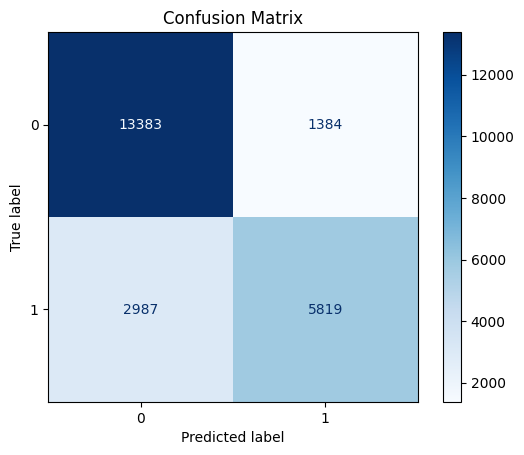


=== Main Metrics ===
Accuracy    = 0.8146
Precision   = 0.8079
Recall      = 0.6608
F1-score    = 0.7270
Specificity = 0.9063

=== ROC Curve ===
ROC-AUC     = 0.8972


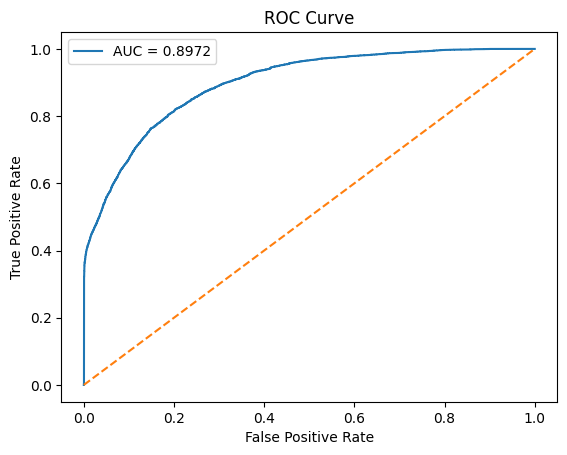

In [61]:
from sklearn.linear_model import LogisticRegression

# Modelo
logreg = LogisticRegression(max_iter=1000)

# Hiperparámetro C
param_grid_log = {
    'C': [0.01, 0.1, 1, 10, 100]
}

# Grid Search
grid_log = GridSearchCV(logreg, param_grid_log, cv=5, scoring='accuracy')

# Entrenar
grid_log.fit(X_train_encoded, y_train)

# Mejor C
print("Mejor C:", grid_log.best_params_)

# Predicción
y_pred_log = grid_log.predict(X_test_encoded)

#CODIGO BASE DE EVALUACIÓN DE MODELOS 

if hasattr(grid_log, "predict_proba"):
    y_score = grid_log.predict_proba(X_test_encoded)[:, 1]  
elif hasattr(grid_log, "decision_function"):
    y_score = grid_log.decision_function(X_test_encoded)
else:
    y_score = None

# MARIZ DE CONFUSIÓN

cm_log = confusion_matrix(y_test, y_pred_log)
tn, fp, fn, tp = cm_log.ravel()

print("=== Confusion Matrix ===")

disp = ConfusionMatrixDisplay(confusion_matrix=cm_log)

disp.plot(
    cmap="Blues",         
)

plt.title("Confusion Matrix")
plt.grid(False)

plt.show()

# METRICAS

accuracy_log = accuracy_score(y_test, y_pred_log)
precision_log = precision_score(y_test, y_pred_log, zero_division=0)
recall_log = recall_score(y_test, y_pred_log, zero_division=0)   
f1_log = f1_score(y_test, y_pred_log, zero_division=0)
specificity_log = tn / (tn + fp) if (tn + fp) > 0 else 0

print("\n=== Main Metrics ===")
print(f"Accuracy    = {accuracy_log:.4f}")
print(f"Precision   = {precision_log:.4f}")
print(f"Recall      = {recall_log:.4f}")
print(f"F1-score    = {f1_log:.4f}")
print(f"Specificity = {specificity_log:.4f}")

# CURVA ROC + AUC

print("\n=== ROC Curve ===")
if y_score is not None:
    fpr, tpr, thresholds = roc_curve(y_test, y_score)
    auc_log = roc_auc_score(y_test, y_score)

    print(f"ROC-AUC     = {auc_log:.4f}")

    plt.figure()
    plt.plot(fpr, tpr, label=f"AUC = {auc_log:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.show()
else:
    print("ROC curve and AUC cannot be computed because the model does not provide probabilities or decision scores.")



Se ha utilizado tanto en Logística como en KNN validación cruzada con 5 particiones (cv=5), lo que implica dividir los datos de entrenamiento en cinco subconjuntos. El modelo se entrena cinco veces utilizando cuatro subconjuntos para entrenamiento y uno para validación, promediando los resultados para obtener una estimación más robusta del rendimiento.

Si eliges C pequeño:
El modelo penaliza más los coeficientes grandes
Los pesos tienden a ser más pequeños
→ Modelo más simple, menos overfitting, pero puede subajustar
Si eliges C grande:
Penalización más débil
Los coeficientes pueden crecer más
→ Modelo más flexible, puede capturar más patrones, pero riesgo de overfitting

En este caso, C = 10 implica una fuerza de regularización de 0.10, relativamente baja. Nos encontramos en el caso de C grande, con un modelo más flexible. 

## 4.3 KNN

In [62]:
# Modelo
knn = KNeighborsClassifier()

# Hiperparámetro k
param_grid_knn = {
    'n_neighbors': [3, 5, 7, 9, 11, 15]
}

# Grid Search
grid_knn = GridSearchCV(knn, param_grid_knn, cv=5, scoring='accuracy')

# Entrenar
grid_knn.fit(X_train_encoded, y_train)

# Mejor k
print("Mejor k:", grid_knn.best_params_)

# Predicción
y_pred_knn = grid_knn.predict(X_test_encoded)


Mejor k: {'n_neighbors': 9}


=== Confusion Matrix ===


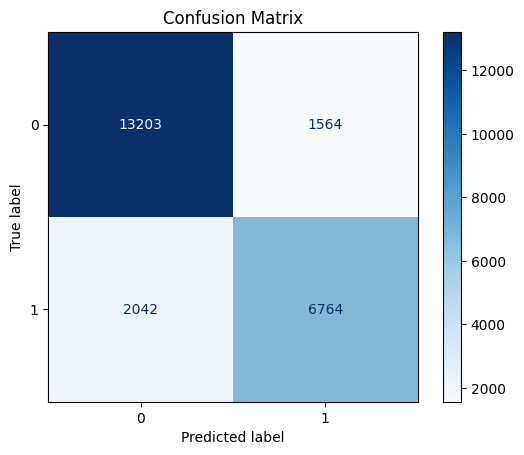


=== Main Metrics ===
Accuracy    = 0.8470
Precision   = 0.8122
Recall      = 0.7681
F1-score    = 0.7895
Specificity = 0.8941

=== ROC Curve ===
ROC-AUC     = 0.9164


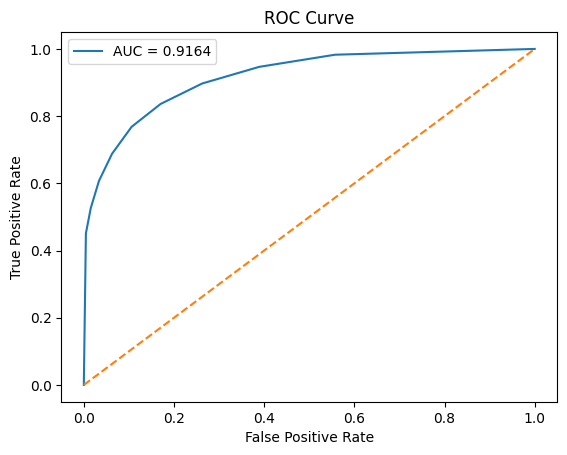

In [63]:

#CODIGO BASE DE EVALUACIÓN DE MODELOS 

if hasattr(grid_knn, "predict_proba"):
    y_score = grid_knn.predict_proba(X_test_encoded)[:, 1]  
elif hasattr(grid_knn, "decision_function"):
    y_score = grid_knn.decision_function(X_test_encoded)
else:
    y_score = None

# MARIZ DE CONFUSIÓN

cm_knn = confusion_matrix(y_test, y_pred_knn)
tn, fp, fn, tp = cm_knn.ravel()

print("=== Confusion Matrix ===")

disp = ConfusionMatrixDisplay(confusion_matrix=cm_knn)

disp.plot(
    cmap="Blues",         
)

plt.title("Confusion Matrix")
plt.grid(False)

plt.show()

# METRICAS

accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn, zero_division=0)
recall_knn = recall_score(y_test, y_pred_knn, zero_division=0)   
f1_knn = f1_score(y_test, y_pred_knn, zero_division=0)
specificity_knn = tn / (tn + fp) if (tn + fp) > 0 else 0

print("\n=== Main Metrics ===")
print(f"Accuracy    = {accuracy_knn:.4f}")
print(f"Precision   = {precision_knn:.4f}")
print(f"Recall      = {recall_knn:.4f}")
print(f"F1-score    = {f1_knn:.4f}")
print(f"Specificity = {specificity_knn:.4f}")

# CURVA ROC + AUC

print("\n=== ROC Curve ===")
if y_score is not None:
    fpr, tpr, thresholds = roc_curve(y_test, y_score)
    auc_knn = roc_auc_score(y_test, y_score)

    print(f"ROC-AUC     = {auc_knn:.4f}")

    plt.figure()
    plt.plot(fpr, tpr, label=f"AUC = {auc_knn:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.show()
else:
    print("ROC curve and AUC cannot be computed because the model does not provide probabilities or decision scores.")

## 4.4 ÁRBOLES DE DECISION (CART)

### Uso de datos normalizados en modelos de árboles

Los modelos basados en árboles de decisión no requieren normalización de las variables, ya que no dependen de distancias ni de la escala de los datos, sino de reglas de decisión basadas en comparaciones.

Sin embargo, en este proyecto se ha optado por utilizar el dataset previamente normalizado también para estos modelos, con el objetivo de mantener la coherencia en el preprocesamiento y facilitar la comparación entre distintos algoritmos.

Dado que la normalización no afecta al funcionamiento de los árboles, esta decisión no perjudica el rendimiento del modelo.


Número de alphas generados: 163


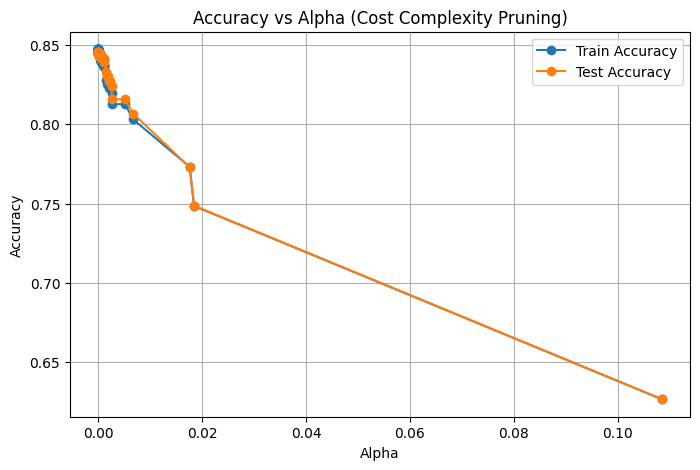


Mejor alpha: 4.148764354684753e-05


In [64]:
# ÁRBOL INICIAL
tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=10,          
    random_state=123
)

tree.fit(X_train_encoded, y_train)

# COST-COMPLEXITY PRUNING PATH
path = tree.cost_complexity_pruning_path(X_train_encoded, y_train)
ccp_alphas = path.ccp_alphas

print("\nNúmero de alphas generados:", len(ccp_alphas))

# ENTRENAR ÁRBOLES PARA CADA ALPHA
trees = []

for alpha in ccp_alphas:
    clf = DecisionTreeClassifier(
        criterion="gini",
        max_depth=10,
        ccp_alpha=alpha,
        random_state=123
    )
    clf.fit(X_train_encoded, y_train)
    trees.append(clf)


# CALCULAR ACCURACY EN TRAIN Y TEST
train_acc = []
test_acc = []

for clf in trees:
    y_train_pred = clf.predict(X_train_encoded)
    y_test_pred = clf.predict(X_test_encoded)
    
    train_acc.append(accuracy_score(y_train, y_train_pred))
    test_acc.append(accuracy_score(y_test, y_test_pred))

# GRÁFICO 
plt.figure(figsize=(8,5))
plt.plot(ccp_alphas, train_acc, marker='o', label="Train Accuracy")
plt.plot(ccp_alphas, test_acc, marker='o', label="Test Accuracy")
plt.xlabel("Alpha")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Alpha (Cost Complexity Pruning)")
plt.legend()
plt.grid()
plt.show()


# SELECCIÓN DEL MEJOR ALPHA
# Elegimos el alpha con mayor accuracy en TEST
best_index = test_acc.index(max(test_acc))
best_alpha = ccp_alphas[best_index]

print("\nMejor alpha:", best_alpha)

=== Confusion Matrix ===


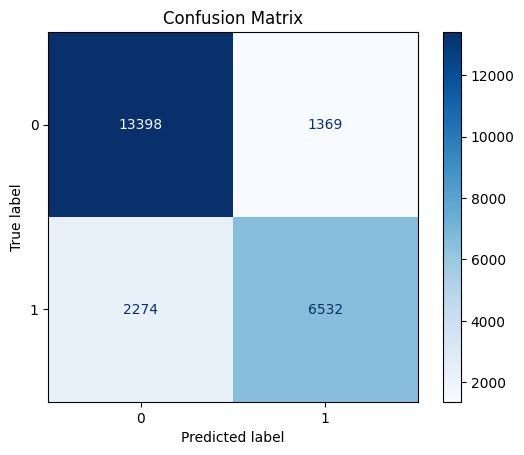


=== Main Metrics ===
Accuracy    = 0.8455
Precision   = 0.8267
Recall      = 0.7418
F1-score    = 0.7819
Specificity = 0.9073

=== ROC Curve ===
ROC-AUC     = 0.9208


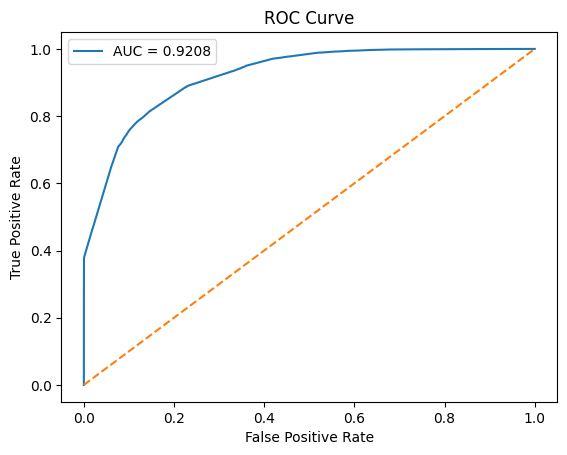

In [65]:
# ENTRENAR MODELO FINAL
final_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=10,
    ccp_alpha=best_alpha,
    random_state=123
)


# EVALUACIÓN FINAL

# Aseguramos que el árbol final esté entrenado
final_tree.fit(X_train_encoded, y_train)

# Predicciones sobre test
y_pred_CART = final_tree.predict(X_test_encoded)

#CODIGO BASE DE EVALUACIÓN DE MODELOS 

if hasattr(final_tree, "predict_proba"):
    y_score = final_tree.predict_proba(X_test_encoded)[:, 1]  
elif hasattr(final_tree, "decision_function"):
    y_score = final_tree.decision_function(X_test_encoded)
else:
    y_score = None

# MARIZ DE CONFUSIÓN

cm_CART = confusion_matrix(y_test, y_pred_CART)
tn, fp, fn, tp = cm_CART.ravel()

print("=== Confusion Matrix ===")

disp = ConfusionMatrixDisplay(confusion_matrix=cm_CART)

disp.plot(
    cmap="Blues",         
)

plt.title("Confusion Matrix")
plt.grid(False)

plt.show()

# METRICAS

accuracy_CART = accuracy_score(y_test, y_pred_CART)
precision_CART = precision_score(y_test, y_pred_CART, zero_division=0)
recall_CART = recall_score(y_test, y_pred_CART, zero_division=0)   
f1_CART = f1_score(y_test, y_pred_CART, zero_division=0)
specificity_CART = tn / (tn + fp) if (tn + fp) > 0 else 0

print("\n=== Main Metrics ===")
print(f"Accuracy    = {accuracy_CART:.4f}")
print(f"Precision   = {precision_CART:.4f}")
print(f"Recall      = {recall_CART:.4f}")
print(f"F1-score    = {f1_CART:.4f}")
print(f"Specificity = {specificity_CART:.4f}")

# CURVA ROC + AUC

print("\n=== ROC Curve ===")
if y_score is not None:
    fpr, tpr, thresholds = roc_curve(y_test, y_score)
    auc_CART = roc_auc_score(y_test, y_score)

    print(f"ROC-AUC     = {auc_CART:.4f}")

    plt.figure()
    plt.plot(fpr, tpr, label=f"AUC = {auc_CART:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.show()
else:
    print("ROC curve and AUC cannot be computed because the model does not provide probabilities or decision scores.")

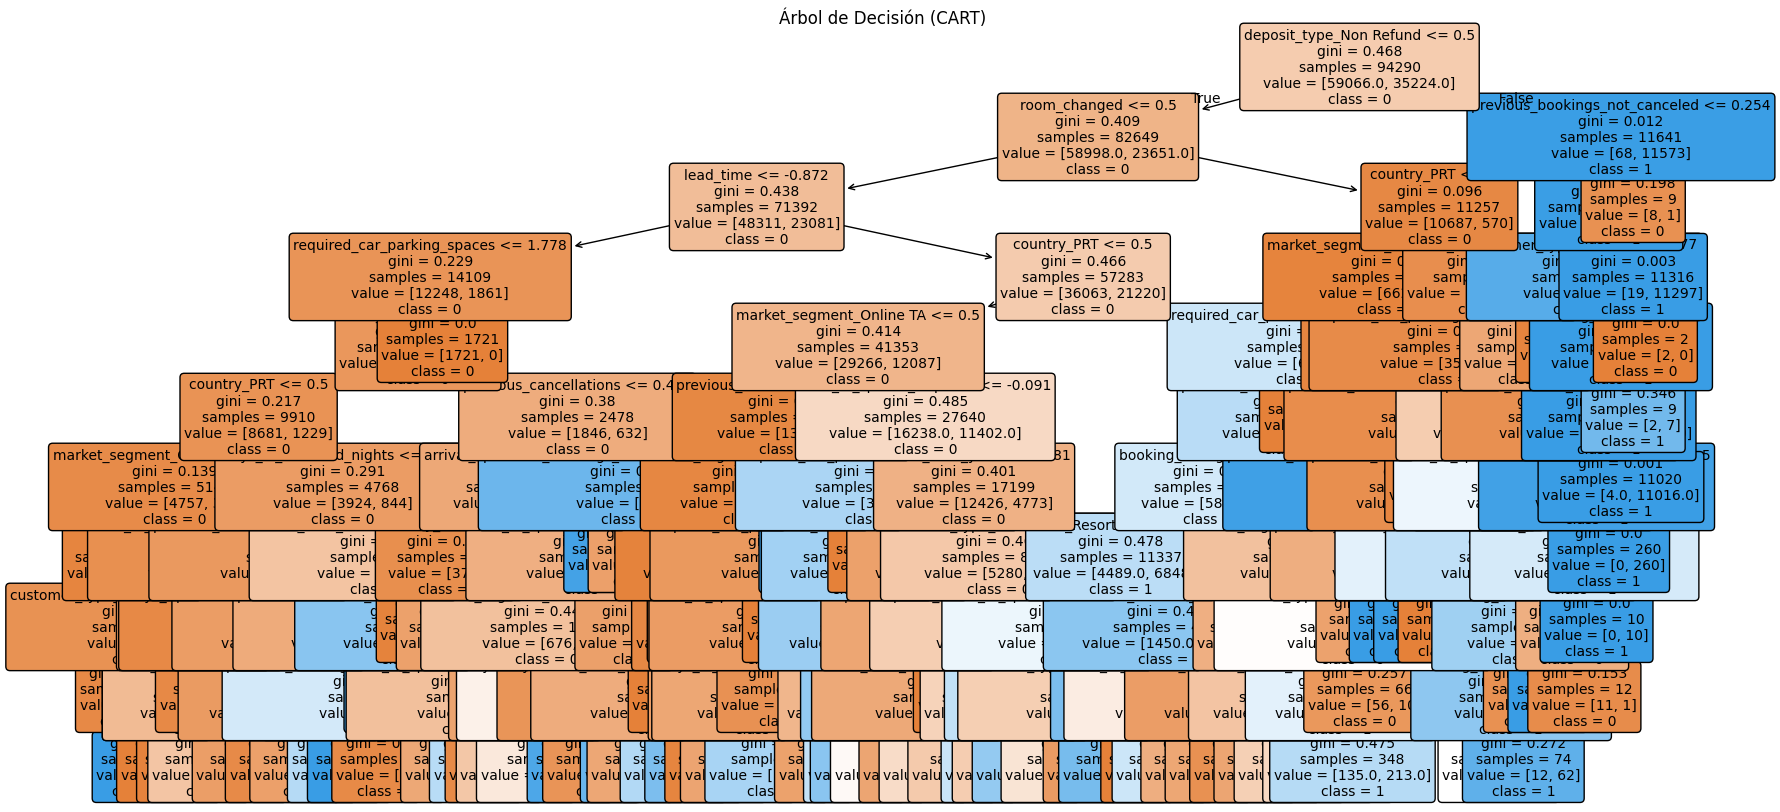

In [66]:
plt.figure(figsize=(20,10))

plot_tree(
    final_tree,
    feature_names=X_train_encoded.columns,
    class_names=["0", "1", "2", "3"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Árbol de Decisión (CART)")
plt.show()

## 4.5 ENSEMBLE

### 4.5.1 Bagging: Random Forest

In [29]:
# MODELO BASE
rf = RandomForestClassifier(random_state=123)

# GRID DE HIPERPARÁMETROS
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10],
    'min_samples_split': [2, 5]
}

# GRID SEARCH
grid_search_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,                  # validación cruzada
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

# ENTRENAR
grid_search_rf.fit(X_train_encoded, y_train)

# MEJORES PARÁMETROS
print("Mejores parámetros:", grid_search_rf.best_params_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Mejores parámetros: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}


=== Confusion Matrix ===


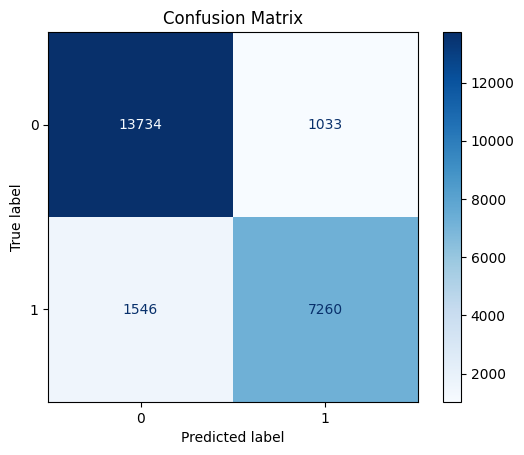


=== Main Metrics ===
Accuracy    = 0.8906
Precision   = 0.8754
Recall      = 0.8244
F1-score    = 0.8492
Specificity = 0.9300

=== ROC Curve ===
ROC-AUC     = 0.9559


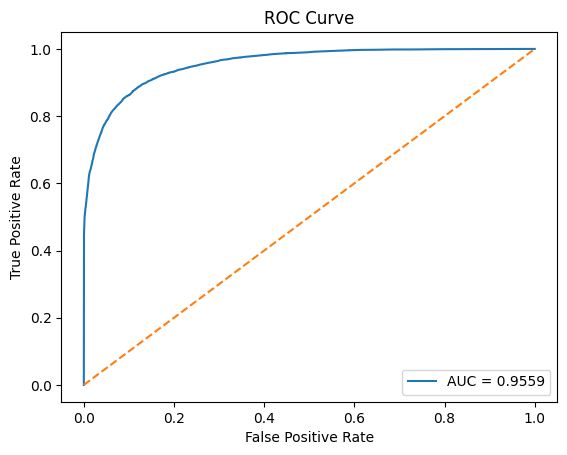

In [30]:
best_rf = grid_search_rf.best_estimator_

# PREDICCIONES
y_pred_rf = best_rf.predict(X_test_encoded)


#CODIGO BASE DE EVALUACIÓN DE MODELOS 

if hasattr(best_rf, "predict_proba"):
    y_score = best_rf.predict_proba(X_test_encoded)[:, 1]  
elif hasattr(best_rf, "decision_function"):
    y_score = best_rf.decision_function(X_test_encoded)
else:
    y_score = None

# MARIZ DE CONFUSIÓN

cm_rf = confusion_matrix(y_test, y_pred_rf)
tn, fp, fn, tp = cm_rf.ravel()

print("=== Confusion Matrix ===")

disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf)

disp.plot(
    cmap="Blues",         
)

plt.title("Confusion Matrix")
plt.grid(False)

plt.show()

# METRICAS

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf, zero_division=0)   
f1_rf = f1_score(y_test, y_pred_rf, zero_division=0)
specificity_rf = tn / (tn + fp) if (tn + fp) > 0 else 0

print("\n=== Main Metrics ===")
print(f"Accuracy    = {accuracy_rf:.4f}")
print(f"Precision   = {precision_rf:.4f}")
print(f"Recall      = {recall_rf:.4f}")
print(f"F1-score    = {f1_rf:.4f}")
print(f"Specificity = {specificity_rf:.4f}")

# CURVA ROC + AUC

print("\n=== ROC Curve ===")
if y_score is not None:
    fpr, tpr, thresholds = roc_curve(y_test, y_score)
    auc_rf = roc_auc_score(y_test, y_score)

    print(f"ROC-AUC     = {auc_rf:.4f}")

    plt.figure()
    plt.plot(fpr, tpr, label=f"AUC = {auc_rf:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.show()
else:
    print("ROC curve and AUC cannot be computed because the model does not provide probabilities or decision scores.")

### 4.5.2 Boosting: Gradient Boosting

Gradient Boosting es un método de boosting que construye modelos uno detrás de otro (secuencialmente), cada nuevo modelo intenta corregir los errores del anterior

In [67]:
# MODELO BASE
gb = GradientBoostingClassifier(random_state=123)

# HIPERPARÁMETROS
param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5]
}

# GRID SEARCH
grid_search_gb = GridSearchCV(
    estimator=gb,
    param_grid=param_grid,
    cv=4,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

# ENTRENAR
grid_search_gb.fit(X_train_encoded, y_train)

# MEJORES PARÁMETROS
print("Mejores parámetros:", grid_search_gb.best_params_)

Fitting 4 folds for each of 8 candidates, totalling 32 fits
Mejores parámetros: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}


=== Confusion Matrix ===


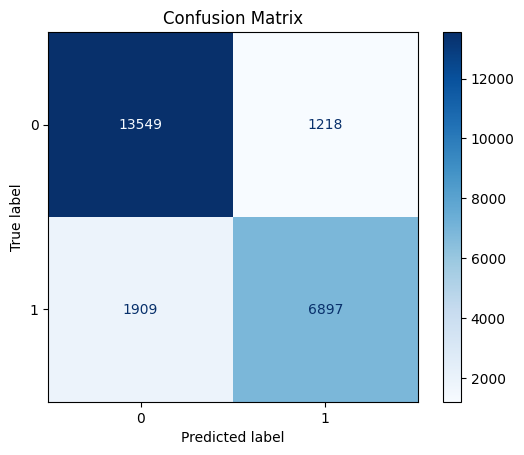


=== Main Metrics ===
Accuracy    = 0.8673
Precision   = 0.8499
Recall      = 0.7832
F1-score    = 0.8152
Specificity = 0.9175

=== ROC Curve ===
ROC-AUC     = 0.9423


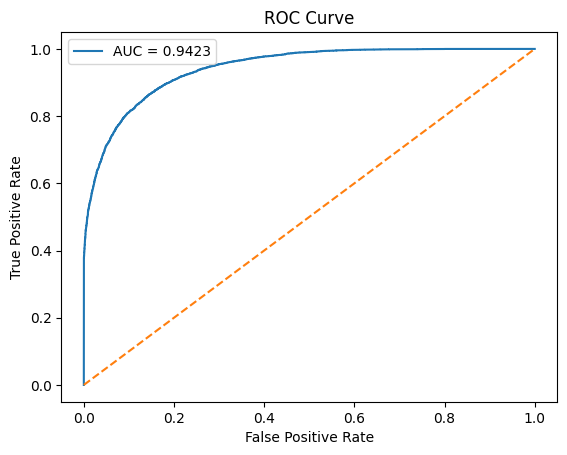

In [68]:
best_gb = grid_search_gb.best_estimator_

# PREDICCIONES
y_pred_gb = best_gb.predict(X_test_encoded)

#CODIGO BASE DE EVALUACIÓN DE MODELOS 

if hasattr(best_gb, "predict_proba"):
    y_score = best_gb.predict_proba(X_test_encoded)[:, 1]  
elif hasattr(best_gb, "decision_function"):
    y_score = best_gb.decision_function(X_test_encoded)
else:
    y_score = None

# MARIZ DE CONFUSIÓN

cm_gb = confusion_matrix(y_test, y_pred_gb)
tn, fp, fn, tp = cm_gb.ravel()

print("=== Confusion Matrix ===")

disp = ConfusionMatrixDisplay(confusion_matrix=cm_gb)

disp.plot(
    cmap="Blues",         
)

plt.title("Confusion Matrix")
plt.grid(False)

plt.show()

# METRICAS

accuracy_gb = accuracy_score(y_test, y_pred_gb)
precision_gb = precision_score(y_test, y_pred_gb, zero_division=0)
recall_gb = recall_score(y_test, y_pred_gb, zero_division=0)   
f1_gb = f1_score(y_test, y_pred_gb, zero_division=0)
specificity_gb = tn / (tn + fp) if (tn + fp) > 0 else 0

print("\n=== Main Metrics ===")
print(f"Accuracy    = {accuracy_gb:.4f}")
print(f"Precision   = {precision_gb:.4f}")
print(f"Recall      = {recall_gb:.4f}")
print(f"F1-score    = {f1_gb:.4f}")
print(f"Specificity = {specificity_gb:.4f}")

# CURVA ROC + AUC

print("\n=== ROC Curve ===")
if y_score is not None:
    fpr, tpr, thresholds = roc_curve(y_test, y_score)
    auc_gb = roc_auc_score(y_test, y_score)

    print(f"ROC-AUC     = {auc_gb:.4f}")

    plt.figure()
    plt.plot(fpr, tpr, label=f"AUC = {auc_gb:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.show()
else:
    print("ROC curve and AUC cannot be computed because the model does not provide probabilities or decision scores.")

### 4.5.3 Voting

Existe Voting Soft y Hard. En Soft se utilizan probabilidades mientras que Hard solo utiliza votos. 

#### Voting Soft

In [69]:
from sklearn.ensemble import VotingClassifier

# MODELO VOTING
voting_model = VotingClassifier(
    estimators=[
        ('lr', grid_log),
        ('knn', grid_knn),
        ('nb', nb_model),
        ('tree', final_tree),
        ('rf', best_rf),
        ('gb', best_gb)
    ],
    voting='soft'   # 🔥 usa probabilidades (mejor)
)

# ENTRENAR
voting_model.fit(X_train_encoded, y_train)

# PREDICCIONES
y_pred_voting = voting_model.predict(X_test_encoded)

=== Confusion Matrix ===


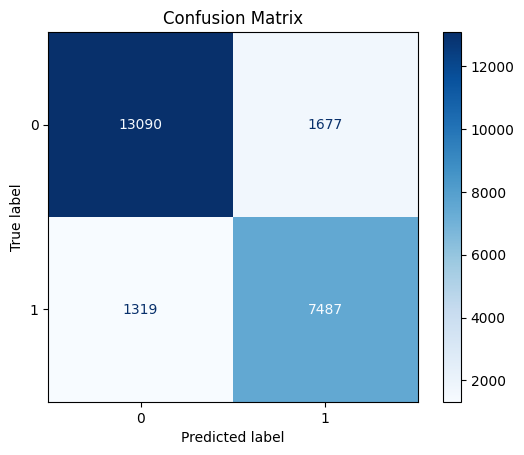


=== Main Metrics ===
Accuracy    = 0.8729
Precision   = 0.8170
Recall      = 0.8502
F1-score    = 0.8333
Specificity = 0.8864

=== ROC Curve ===
ROC-AUC     = 0.9414


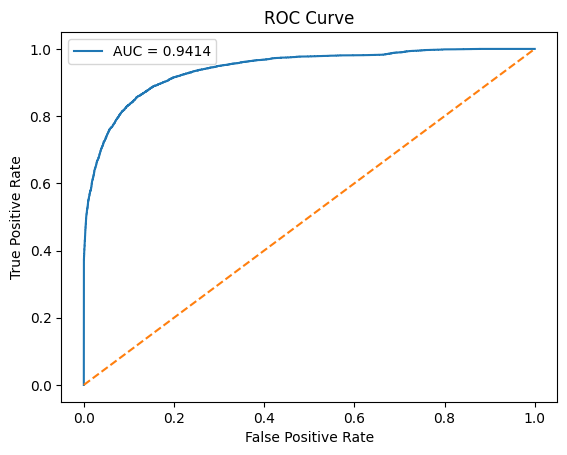

In [70]:
#CODIGO BASE DE EVALUACIÓN DE MODELOS 

if hasattr(voting_model, "predict_proba"):
    y_score = voting_model.predict_proba(X_test_encoded)[:, 1]  
elif hasattr(voting_model, "decision_function"):
    y_score = voting_model.decision_function(X_test_encoded)
else:
    y_score = None

# MARIZ DE CONFUSIÓN

cm_vot = confusion_matrix(y_test, y_pred_voting)
tn, fp, fn, tp = cm_vot.ravel()

print("=== Confusion Matrix ===")

disp = ConfusionMatrixDisplay(confusion_matrix=cm_vot)

disp.plot(
    cmap="Blues",         
)

plt.title("Confusion Matrix")
plt.grid(False)

plt.show()

# METRICAS

accuracy_vot = accuracy_score(y_test, y_pred_voting)
precision_vot = precision_score(y_test, y_pred_voting, zero_division=0)
recall_vot = recall_score(y_test, y_pred_voting, zero_division=0)   
f1_vot = f1_score(y_test, y_pred_voting, zero_division=0)
specificity_vot = tn / (tn + fp) if (tn + fp) > 0 else 0

print("\n=== Main Metrics ===")
print(f"Accuracy    = {accuracy_vot:.4f}")
print(f"Precision   = {precision_vot:.4f}")
print(f"Recall      = {recall_vot:.4f}")
print(f"F1-score    = {f1_vot:.4f}")
print(f"Specificity = {specificity_vot:.4f}")

# CURVA ROC + AUC

print("\n=== ROC Curve ===")
if y_score is not None:
    fpr, tpr, thresholds = roc_curve(y_test, y_score)
    auc_vot = roc_auc_score(y_test, y_score)

    print(f"ROC-AUC     = {auc_vot:.4f}")

    plt.figure()
    plt.plot(fpr, tpr, label=f"AUC = {auc_vot:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.show()
else:
    print("ROC curve and AUC cannot be computed because the model does not provide probabilities or decision scores.")

#### Voting Hard

In [71]:
# MODELO VOTING
voting_model_hard = VotingClassifier(
    estimators=[
        ('lr', grid_log),
        ('knn', grid_knn),
        ('nb', nb_model),
        ('tree', final_tree),
        ('rf', best_rf),
        ('gb', best_gb)
    ],
    voting='hard'   
)

# ENTRENAR
voting_model_hard.fit(X_train_encoded, y_train)

# PREDICCIONES
y_pred_voting_hard = voting_model_hard.predict(X_test_encoded)

=== Confusion Matrix ===


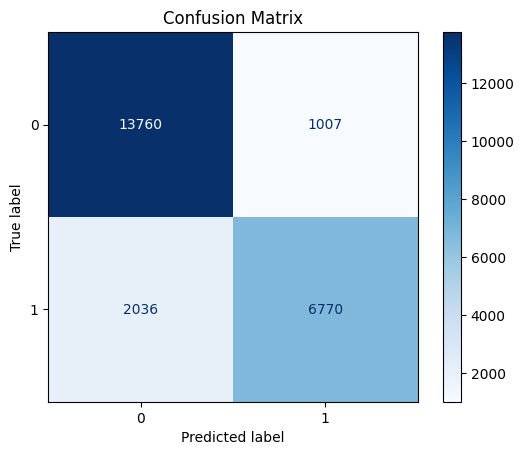


=== Main Metrics ===
Accuracy    = 0.8709
Precision   = 0.8705
Recall      = 0.7688
F1-score    = 0.8165
Specificity = 0.9318

=== ROC Curve ===
ROC curve and AUC cannot be computed because the model does not provide probabilities or decision scores.


In [73]:
#CODIGO BASE DE EVALUACIÓN DE MODELOS 

if hasattr(voting_model_hard, "predict_proba"):
    y_score = voting_model_hard.predict_proba(X_test_encoded)[:, 1]  
elif hasattr(voting_model_hard, "decision_function"):
    y_score = voting_model_hard.decision_function(X_test_encoded)
else:
    y_score = None

# MARIZ DE CONFUSIÓN

cm_vot_hard = confusion_matrix(y_test, y_pred_voting_hard)
tn, fp, fn, tp = cm_vot_hard.ravel()

print("=== Confusion Matrix ===")

disp = ConfusionMatrixDisplay(confusion_matrix=cm_vot_hard)

disp.plot(
    cmap="Blues",         
)

plt.title("Confusion Matrix")
plt.grid(False)

plt.show()

# METRICAS

accuracy_vot_hard = accuracy_score(y_test, y_pred_voting_hard)
precision_vot_hard = precision_score(y_test, y_pred_voting_hard, zero_division=0)
recall_vot_hard = recall_score(y_test, y_pred_voting_hard, zero_division=0)   
f1_vot_hard = f1_score(y_test, y_pred_voting_hard, zero_division=0)
specificity_vot_hard = tn / (tn + fp) if (tn + fp) > 0 else 0

print("\n=== Main Metrics ===")
print(f"Accuracy    = {accuracy_vot_hard:.4f}")
print(f"Precision   = {precision_vot_hard:.4f}")
print(f"Recall      = {recall_vot_hard:.4f}")
print(f"F1-score    = {f1_vot_hard:.4f}")
print(f"Specificity = {specificity_vot_hard:.4f}")

# CURVA ROC + AUC

print("\n=== ROC Curve ===")
if y_score is not None:
    fpr, tpr, thresholds = roc_curve(y_test, y_score)
    auc_vot_hard = roc_auc_score(y_test, y_score)

    print(f"ROC-AUC     = {auc_vot_hard:.4f}")

    plt.figure()
    plt.plot(fpr, tpr, label=f"AUC = {auc_vot_hard:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.show()
else:
    print("ROC curve and AUC cannot be computed because the model does not provide probabilities or decision scores.")

## 4.6 REDES NEURONALES

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Mejores hiperparámetros:
{'hidden_layer_sizes': (20,), 'learning_rate_init': 0.01, 'solver': 'adam'}

Mejor accuracy medio en validación cruzada:
0.8606639092162478

Resumen de resultados de validación cruzada:
  param_hidden_layer_sizes  param_learning_rate_init param_solver  \
3                    (20,)                     0.010         adam   
2                    (20,)                     0.001         adam   
5                 (10, 10)                     0.010         adam   
4                 (10, 10)                     0.001         adam   
1                    (10,)                     0.010         adam   
0                    (10,)                     0.001         adam   

   mean_train_score  mean_test_score  rank_test_score  
3          0.868634         0.860664                1  
2          0.869541         0.860218                2  
5          0.864439         0.858119                3  
4          0.863644  

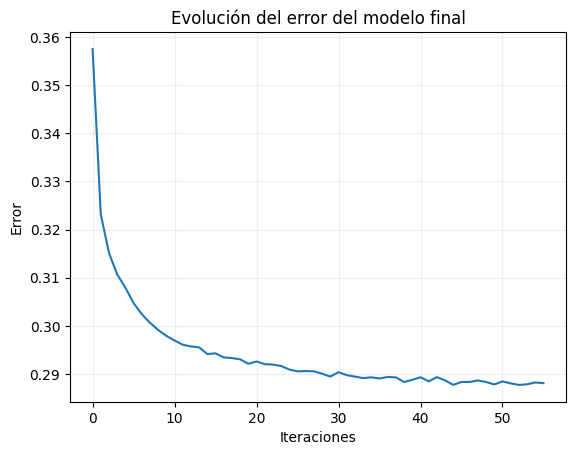


Modelo final:
MLPClassifier(hidden_layer_sizes=(20,), learning_rate_init=0.01, max_iter=500,
              random_state=123)

Número de variables de entrada:
52

Número de salidas:
1

Dimensiones de las matrices de pesos:
Capa 0 → 1: (52, 20)
Capa 1 → 2: (20, 1)


In [74]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV

# 1. DEFINIR LAS OPCIONES QUE QUIERO PROBAR
# Decidir qué arquitecturas de red, learning rates y solver
# Esta es la parte donde realmente se selecciona el modelo.

arquitecturas = [(10,), (20,), (10, 10)]
learning_rates = [0.001, 0.01]
solvers = ["adam"]

parametros = {
    "hidden_layer_sizes": arquitecturas,
    "learning_rate_init": learning_rates,
    "solver": solvers
}

# 2. CREAR EL MODELO BASE
# Este modelo base todavía NO es el modelo final.
# Solo es la plantilla que GridSearchCV va a usar para probar
# distintas combinaciones de hiperparámetros.

modelo_base = MLPClassifier(
    max_iter=500,
    random_state=123
)

# 3. BUSCAR EL MEJOR MODELO CON VALIDACIÓN CRUZADA
# GridSearchCV prueba todas las combinaciones posibles de:
# - hidden_layer_sizes
# - learning_rate_init
# - solver
# y usa validación cruzada para comparar resultados.

busqueda = GridSearchCV(
    estimator=modelo_base,
    param_grid=parametros,
    scoring="accuracy",
    cv=3,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

# Aquí empieza la búsqueda real del mejor modelo
busqueda.fit(X_train_encoded, y_train)

# 4. GUARDAR EL MEJOR MODELO ENCONTRADO

modelo_redes = busqueda.best_estimator_

print("Mejores hiperparámetros:")
print(busqueda.best_params_)

print("\nMejor accuracy medio en validación cruzada:")
print(busqueda.best_score_)

# 5. ENTRENAR EL MEJOR MODELO

modelo_redes.fit(X_train_encoded, y_train)

# 6. HACER PREDICCIONES CON EL MODELO FINAL

y_pred_redes = modelo_redes.predict(X_test_encoded)

# 7. VER LOS RESULTADOS DE TODAS LAS COMBINACIONES PROBADAS

resultados_cv = pd.DataFrame(busqueda.cv_results_)

columnas = [
    "param_hidden_layer_sizes",
    "param_learning_rate_init",
    "param_solver",
    "mean_train_score",
    "mean_test_score",
    "rank_test_score"
]

print("\nResumen de resultados de validación cruzada:")
print(resultados_cv[columnas].sort_values("rank_test_score").head(10))

# 8. GRÁFICO DE LA CURVA DE ERROR DEL MODELO FINAL
# Solo existe si el solver es 'adam'. Si el mejor modelo usa 'lbfgs', no habrá loss_curve_.

if hasattr(modelo_redes, "loss_curve_"):
    plt.figure()
    plt.plot(modelo_redes.loss_curve_)
    plt.title("Evolución del error del modelo final")
    plt.xlabel("Iteraciones")
    plt.ylabel("Error")
    plt.grid(alpha=0.2)
    plt.show()
else:
    print("\nEl modelo final usa solver='lbfgs', así que no tiene loss_curve_.")

# 9. INFORMACIÓN DEL MODELO FINAL
# Aquí simplemente inspeccionamos el modelo elegido.

print("\nModelo final:")
print(modelo_redes)

print("\nNúmero de variables de entrada:")
print(modelo_redes.n_features_in_)

print("\nNúmero de salidas:")
print(modelo_redes.n_outputs_)

print("\nDimensiones de las matrices de pesos:")
for i, capa in enumerate(modelo_redes.coefs_):
    print(f"Capa {i} → {i+1}: {capa.shape}")

=== Confusion Matrix ===


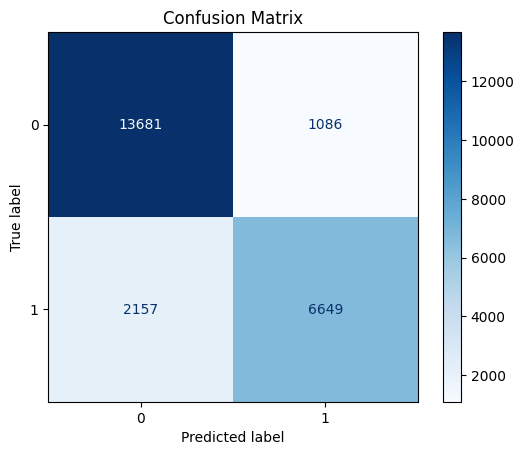


=== Main Metrics ===
Accuracy    = 0.8624
Precision   = 0.8596
Recall      = 0.7551
F1-score    = 0.8039
Specificity = 0.9265

=== ROC Curve ===
ROC-AUC     = 0.9397


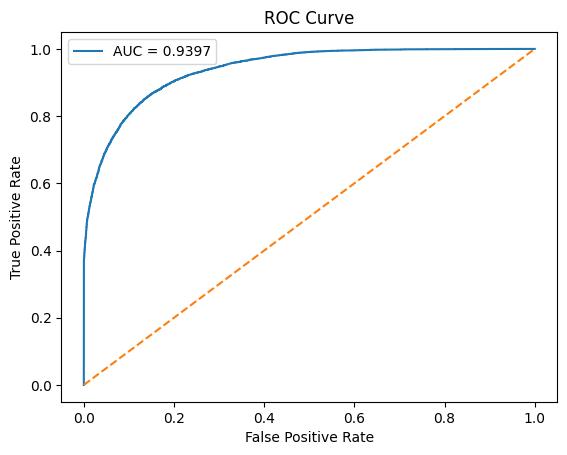

In [77]:
#CODIGO BASE DE EVALUACIÓN DE MODELOS 

if hasattr(modelo_redes, "predict_proba"):
    y_score = modelo_redes.predict_proba(X_test_encoded)[:, 1]  
elif hasattr(modelo_redes, "decision_function"):
    y_score = modelo_redes.decision_function(X_test_encoded)
else:
    y_score = None

# MARIZ DE CONFUSIÓN

cm_redes = confusion_matrix(y_test, y_pred_redes)
tn, fp, fn, tp = cm_redes.ravel()

print("=== Confusion Matrix ===")

disp = ConfusionMatrixDisplay(confusion_matrix=cm_redes)

disp.plot(
    cmap="Blues",         
)

plt.title("Confusion Matrix")
plt.grid(False)

plt.show()

# METRICAS

accuracy_redes = accuracy_score(y_test, y_pred_redes)
precision_redes = precision_score(y_test, y_pred_redes, zero_division=0)
recall_redes = recall_score(y_test,y_pred_redes, zero_division=0)   
f1_redes = f1_score(y_test, y_pred_redes, zero_division=0)
specificity_redes = tn / (tn + fp) if (tn + fp) > 0 else 0

print("\n=== Main Metrics ===")
print(f"Accuracy    = {accuracy_redes:.4f}")
print(f"Precision   = {precision_redes:.4f}")
print(f"Recall      = {recall_redes:.4f}")
print(f"F1-score    = {f1_redes:.4f}")
print(f"Specificity = {specificity_redes:.4f}")

# CURVA ROC + AUC

print("\n=== ROC Curve ===")
if y_score is not None:
    fpr, tpr, thresholds = roc_curve(y_test, y_score)
    auc_redes = roc_auc_score(y_test, y_score)

    print(f"ROC-AUC     = {auc_redes:.4f}")

    plt.figure()
    plt.plot(fpr, tpr, label=f"AUC = {auc_redes:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.show()
else:
    print("ROC curve and AUC cannot be computed because the model does not provide probabilities or decision scores.")

# 6. Comparación y selección del modelo con mejor rendimiento

In [79]:
models = ["redes", "nb", "gb", "vot", "vot_hard", "log", "knn", "CART", "rf"]

data = {
    "model": models,
    "accuracy": [
        accuracy_redes, accuracy_nb, accuracy_gb, accuracy_vot,
        accuracy_vot_hard, accuracy_log, accuracy_knn, accuracy_CART, accuracy_rf
    ],
    "precision": [
        precision_redes, precision_nb, precision_gb, precision_vot,
        precision_vot_hard, precision_log, precision_knn, precision_CART, precision_rf
    ],
    "recall": [
        recall_redes, recall_nb, recall_gb, recall_vot,
        recall_vot_hard, recall_log, recall_knn, recall_CART, recall_rf
    ],
    "f1": [
        f1_redes, f1_nb, f1_gb, f1_vot,
        f1_vot_hard, f1_log, f1_knn, f1_CART, f1_rf
    ],
    "specificity": [
        specificity_redes, specificity_nb, specificity_gb, specificity_vot,
        specificity_vot_hard, specificity_log, specificity_knn, specificity_CART, specificity_rf
    ],
    "auc": [
        auc_redes, auc_nb, auc_gb, auc_vot,
        "No tiene", auc_log, auc_knn, auc_CART, auc_rf
    ],
}

df_metrics = pd.DataFrame(data)
df_metrics

,model,accuracy,precision,recall,f1,specificity,auc
0,redes,0.862427,0.859599,0.755053,0.803942,0.926458,0.9397
1,nb,0.582022,0.470657,0.953554,0.630240,0.360466,0.828077
2,gb,0.867348,0.849908,0.783216,0.815200,0.917519,0.942303
3,vot,0.872905,0.817001,0.850216,0.833278,0.886436,0.941399
4,vot_hard,0.870912,0.870516,0.768794,0.816499,0.931807,No tiene
5,log,0.814576,0.807858,0.660799,0.726966,0.906278,0.897218
6,knn,0.847028,0.812200,0.768113,0.789541,0.894088,0.916362
7,CART,0.845459,0.826731,0.741767,0.781948,0.907293,0.92078
8,rf,0.890595,0.875437,0.824438,0.849172,0.930047,0.955917


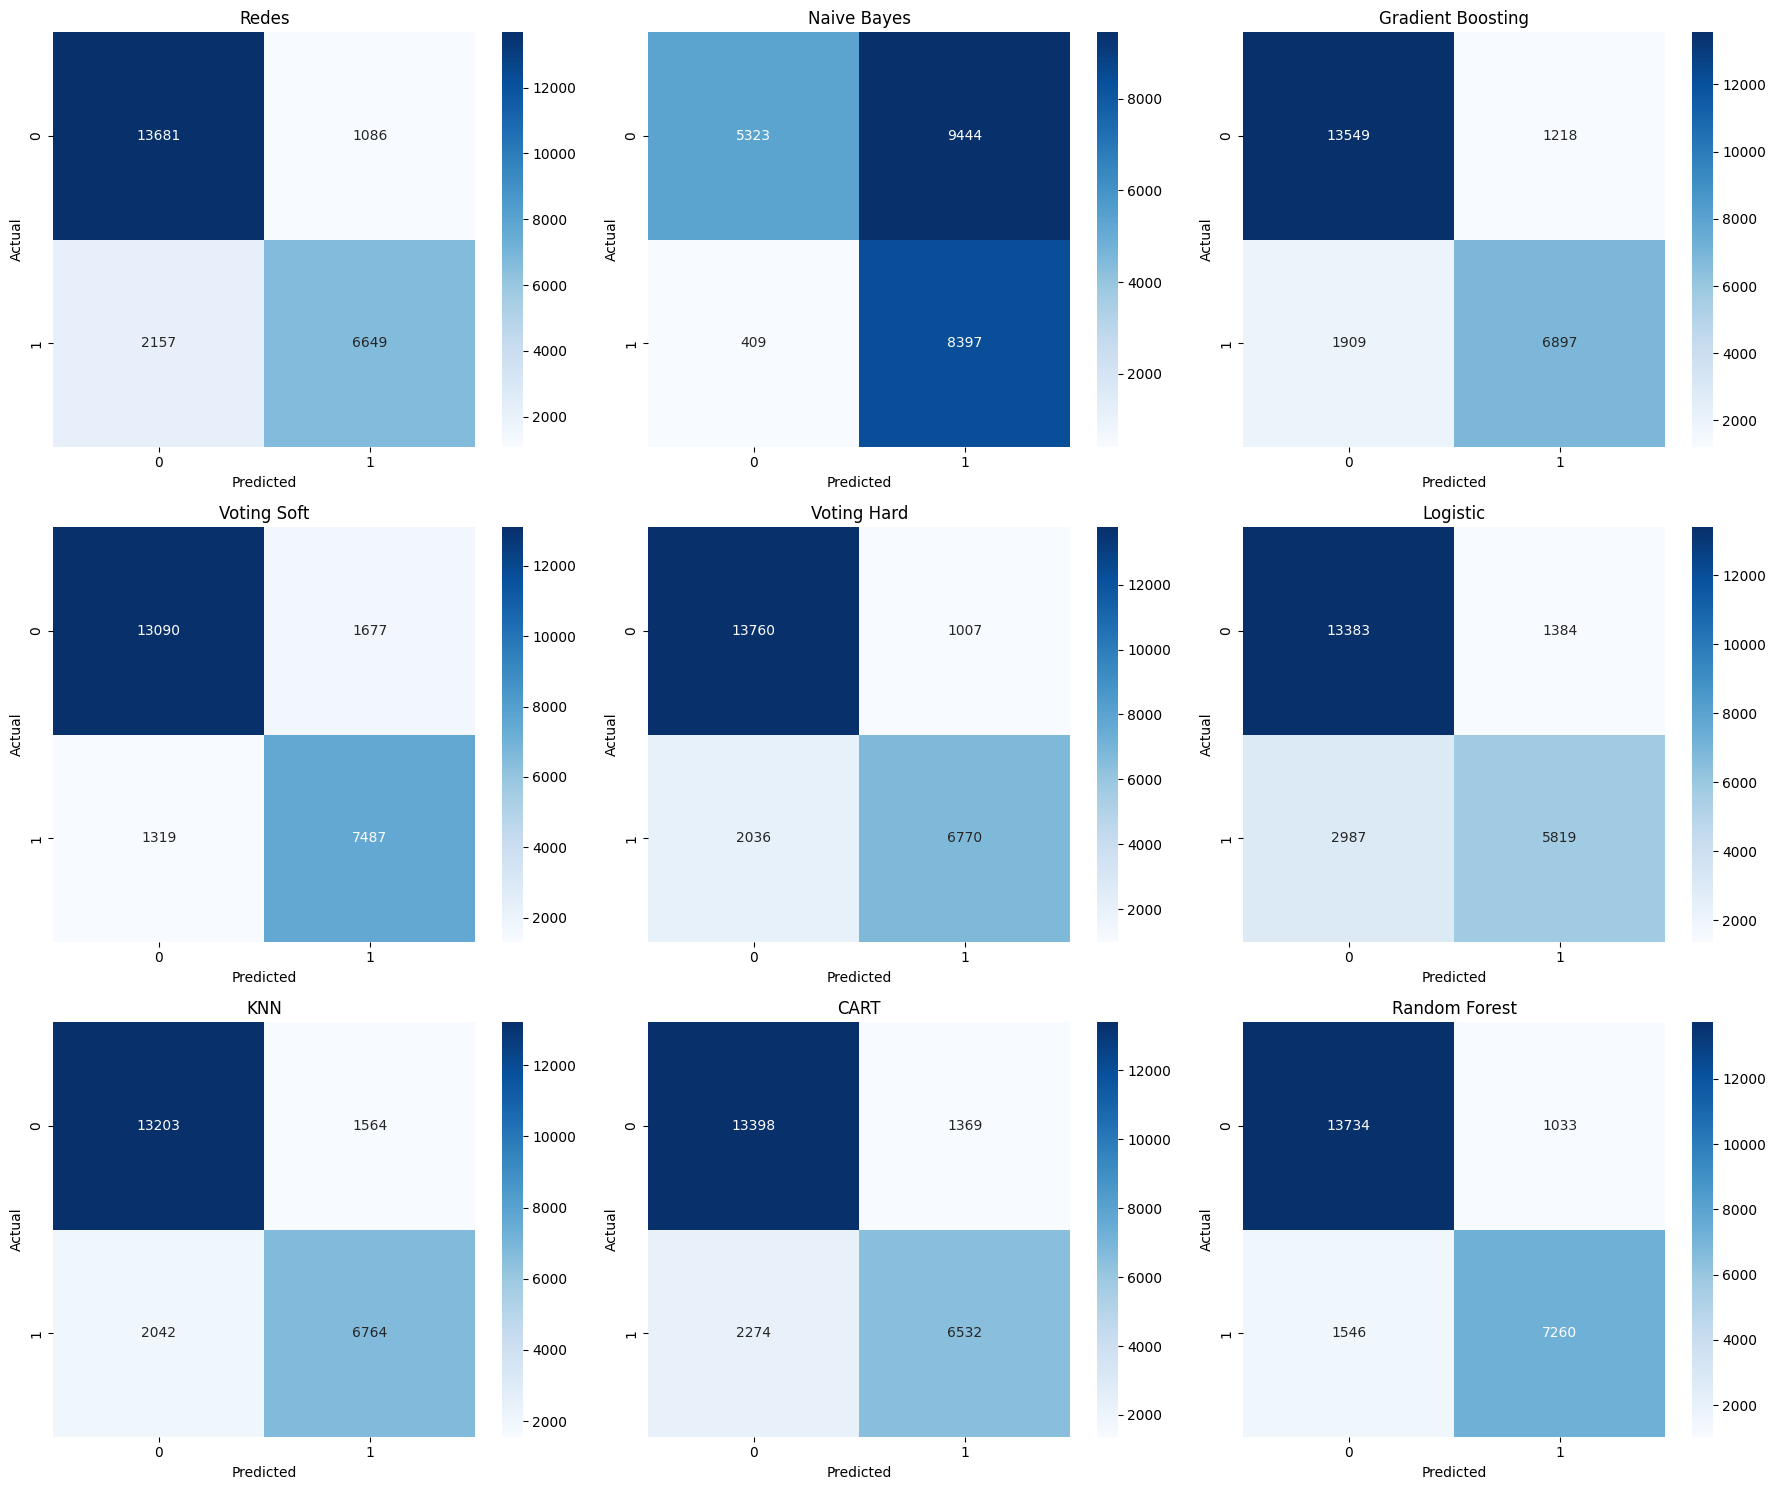

In [80]:
cm_redes = confusion_matrix(y_test, y_pred_redes)
cm_nb = confusion_matrix(y_test, y_pred_nb)
cm_gb = confusion_matrix(y_test, y_pred_gb)
cm_vot = confusion_matrix(y_test, y_pred_voting)
cm_vot_hard = confusion_matrix(y_test, y_pred_voting_hard)
cm_log = confusion_matrix(y_test, y_pred_log)
cm_knn = confusion_matrix(y_test, y_pred_knn)
cm_CART = confusion_matrix(y_test, y_pred_CART)
cm_rf = confusion_matrix(y_test, y_pred_rf)

# Diccionario con modelos y matrices
conf_matrices = {
    "Redes": cm_redes,
    "Naive Bayes": cm_nb,
    "Gradient Boosting": cm_gb,
    "Voting Soft": cm_vot,
    "Voting Hard": cm_vot_hard,
    "Logistic": cm_log,
    "KNN": cm_knn,
    "CART": cm_CART,
    "Random Forest": cm_rf
}

# Crear figura 3x3
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.flatten()

# Dibujar cada matriz
for i, (name, cm) in enumerate(conf_matrices.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[i])
    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

plt.tight_layout()
plt.show()

Se decide elegir el modelo de Random Forest ya que presenta las mejores métricas en prácticamente todos los campos.

## 6.1 Explicabilidad  e interpretabilidad del modelo de Random Forest seleccionado como el mejor modelo

### Recordamos las métricas del modelo

El modelo Random Forest presenta un rendimiento sólido en la predicción de cancelaciones hoteleras, con una accuracy de 0.8906, lo que implica que aproximadamente el 89% de las reservas son correctamente clasificadas. Analizando la matriz de confusión, el modelo acierta 13.734 reservas no canceladas y 7.260 canceladas, mientras que comete 1.033 falsos positivos (predice cancelación cuando no la hay) y 1.546 falsos negativos (no detecta cancelaciones reales). Esto se refleja en el classification report, donde el modelo muestra mejor desempeño en la clase 0 (no cancelación) con un recall de 0.93 frente a 0.82 en la clase 1, indicando que algunas cancelaciones son más difíciles de detectar. Además, la curva ROC presenta un AUC de 0.9559, lo que demuestra una excelente capacidad del modelo para distinguir entre reservas canceladas y no canceladas.

### Explicacion de que variables considera el modelo más importantes 

                        feature  importance
0                     lead_time    0.162885
47      deposit_type_Non Refund    0.106790
12                          adr    0.106409
36                  country_PRT    0.075857
14    total_of_special_requests    0.060434
3          stays_in_week_nights    0.049368
15                 room_changed    0.033069
2       stays_in_weekend_nights    0.031249
8        previous_cancellations    0.030793
1             arrival_date_year    0.028699
42     market_segment_Online TA    0.026256
13  required_car_parking_spaces    0.023353
10              booking_changes    0.021461
50      customer_type_Transient    0.018905
4                        adults    0.017009


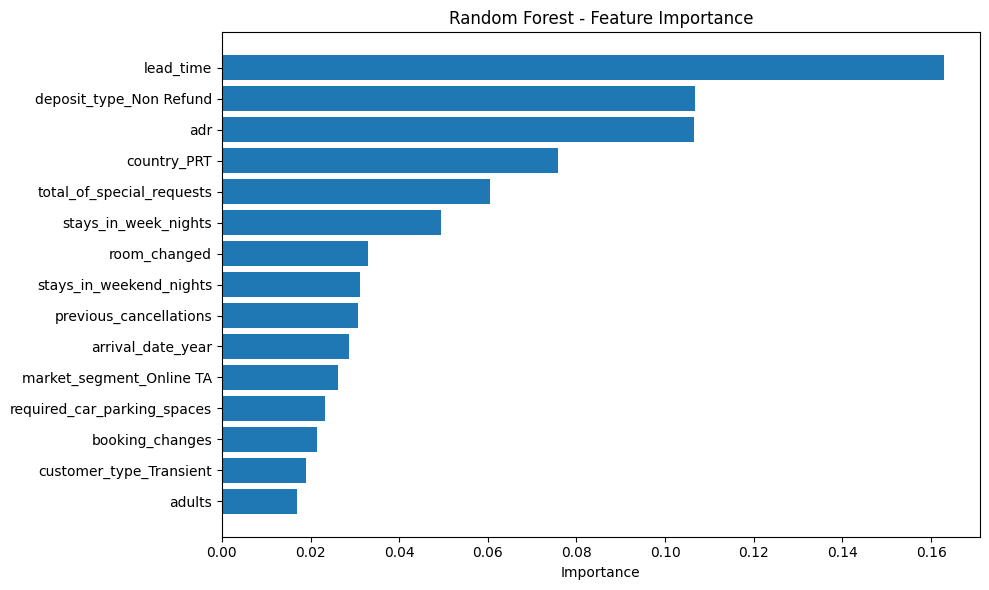

In [32]:
feature_importance = pd.DataFrame({
    "feature": X_train_encoded.columns,
    "importance": best_rf.feature_importances_
}).sort_values("importance", ascending=False)

print(feature_importance.head(15))

plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance["feature"].head(15),
    feature_importance["importance"].head(15)
)
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("Random Forest - Feature Importance")
plt.tight_layout()
plt.show()

El análisis de importancia de variables del Random Forest muestra que las variables más influyentes en la predicción son lead_time (0.1629), deposit_type_Non Refund (0.1068), adr (0.1064) y country_PRT (0.0759). Esto indica que el tiempo de antelación con el que se realiza la reserva, el tipo de depósito, el precio medio diario y el país de origen del cliente son factores clave en la predicción de cancelaciones.

### Permutation importance: desordenamos las variabes y vemos cuanto empero el accuracy


Realizamos permutation importance en una muestra ya que tenemos demasiadas observaciones para ejecutarlas todas 

In [75]:
X_perm = X_test_encoded.sample(min(500, len(X_test_encoded)), random_state=123)
y_perm = y_test.loc[X_perm.index]

print("Muestra para permutation importance:", X_perm.shape)

Muestra para permutation importance: (500, 52)


In [76]:
perm = permutation_importance(
    best_rf,
    X_perm,
    y_perm,
    n_repeats=3,
    random_state=123,
    scoring="accuracy"
)

perm_importance = pd.DataFrame({
    "feature": X_perm.columns,
    "importance_mean": perm.importances_mean
}).sort_values("importance_mean", ascending=False)

print(perm_importance.head(15))

                          feature  importance_mean
14      total_of_special_requests         0.073333
0                       lead_time         0.054667
36                    country_PRT         0.040667
42       market_segment_Online TA         0.037333
47        deposit_type_Non Refund         0.031333
15                   room_changed         0.020000
13    required_car_parking_spaces         0.012000
50        customer_type_Transient         0.011333
1               arrival_date_year         0.010667
35                  country_Other         0.008667
16             hotel_Resort Hotel         0.008667
12                            adr         0.008667
8          previous_cancellations         0.007333
21        arrival_date_month_July         0.004667
51  customer_type_Transient-Party         0.004000


El análisis de permutation importance confirma y refuerza los resultados anteriores desde una perspectiva más robusta, ya que mide el impacto de cada variable en el rendimiento del modelo. En este caso, las variables más relevantes son total_of_special_requests (0.0733), lead_time (0.0547) y country_PRT (0.0407). Esto significa que al desordenar estas variables, el accuracy del modelo disminuye significativamente, lo que evidencia su importancia en la predicción. Destaca especialmente total_of_special_requests, indicando que el número de peticiones especiales del cliente es un factor clave para distinguir entre reservas que se cancelan y las que no.

### PDP (Partial Dependence Plots): efecto medio de variables mas importantes

In [35]:
top_features = perm_importance["feature"].head(3).tolist()
print("Variables para PDP:", top_features)

Variables para PDP: ['total_of_special_requests', 'lead_time', 'country_PRT']


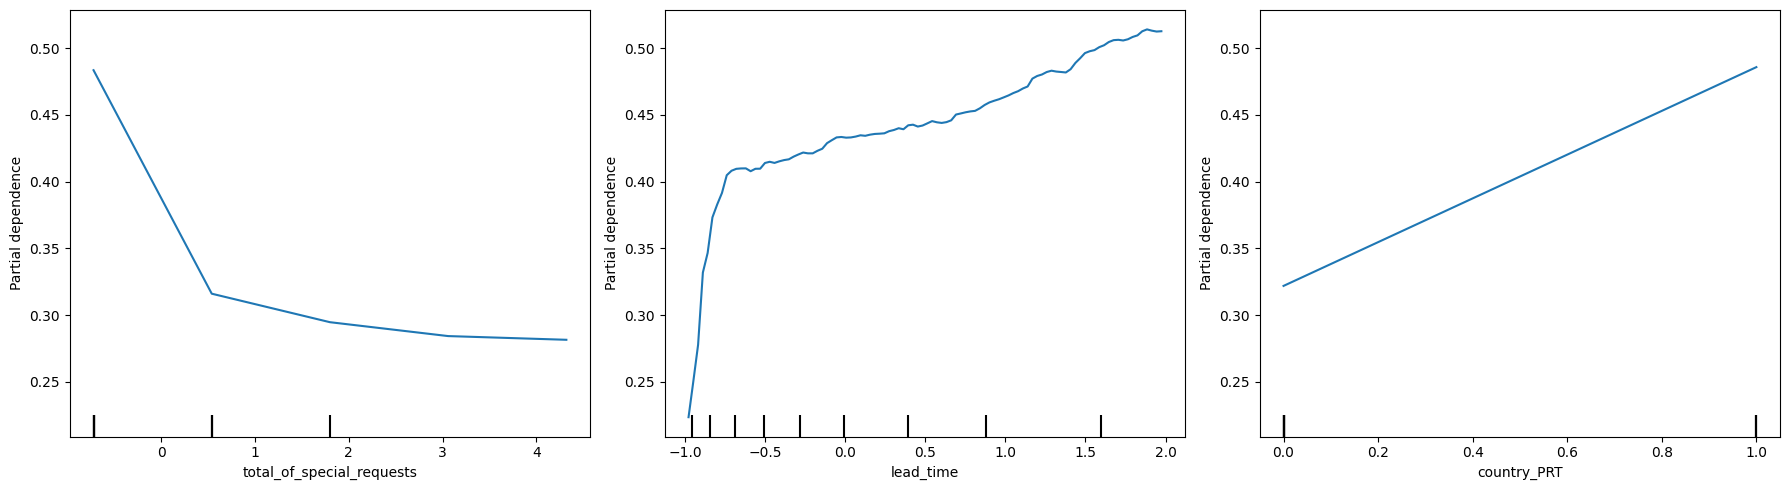

In [36]:
X_pdp = X_test_encoded.sample(500, random_state=123)
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

PartialDependenceDisplay.from_estimator(
    best_rf,
    X_pdp,
    top_features,
    ax=ax
)

plt.tight_layout()
plt.show()

Los gráficos PDP permiten analizar el efecto medio de las variables sobre la probabilidad de cancelación. En el caso de total_of_special_requests, se observa una relación decreciente: a medida que aumentan las peticiones especiales, disminuye la probabilidad de cancelación, lo que sugiere que clientes más implicados son menos propensos a cancelar. Por otro lado, el PDP de lead_time muestra una tendencia creciente, indicando que cuanto mayor es la antelación de la reserva, mayor es la probabilidad de cancelación. Finalmente, en country_PRT se observa que los clientes procedentes de Portugal presentan una mayor probabilidad media de cancelación

### SHAP LOCAL DE MUESTRA CANCELADA

In [48]:
# Evita errores de programción
def get_shap_class_1(shap_values):
    """
    Devuelve los SHAP values de la clase positiva en clasificación binaria.
    Compatible con distintos formatos de salida.
    """
    if isinstance(shap_values, list):
        return shap_values[1]
    elif len(np.array(shap_values).shape) == 3:
        return shap_values[:, :, 1]
    else:
        return shap_values

In [49]:
#BUSCAMOS UNA MUESTRA CANCELADA
# Filtrar las observaciones del test que son clase 1
X_test_1 = X_test_encoded[y_test == 1]

# Elegir una sola
X_one = X_test_1.sample(1, random_state=121)

print("Observación elegida (clase 1):", X_one.shape)

Observación elegida (clase 1): (1, 52)


In [50]:
explainer = shap.TreeExplainer(best_rf)

shap_values_one = explainer.shap_values(
    X_one,
    check_additivity=False
)

shap_values_one_class1 = get_shap_class_1(shap_values_one)

In [51]:
print("Predicción:", best_rf.predict(X_one)[0])
print("Probabilidad clase 1:", best_rf.predict_proba(X_one)[0][1])

Predicción: 1
Probabilidad clase 1: 0.9616666666666666


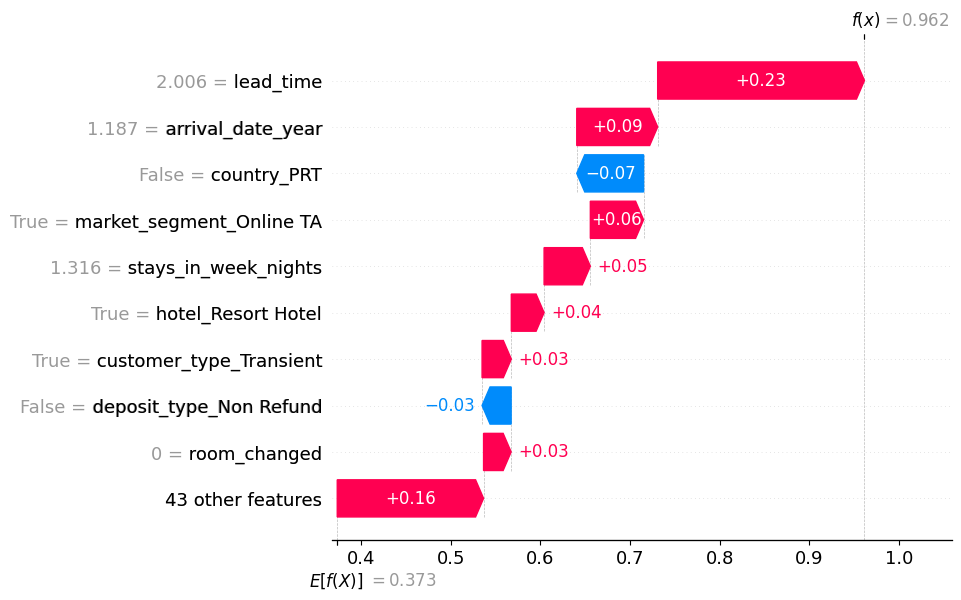

In [52]:
expected_value = explainer.expected_value

if isinstance(expected_value, list):
    expected_value = expected_value[1]
elif hasattr(expected_value, "__len__") and len(np.array(expected_value).flatten()) > 1:
    expected_value = np.array(expected_value).flatten()[1]

sample_explanation = shap.Explanation(
    values=shap_values_one_class1[0],
    base_values=expected_value,
    data=X_one.iloc[0].values,
    feature_names=X_one.columns.tolist()
)

shap.plots.waterfall(sample_explanation, max_display=10)

In [42]:
shap_local_df = pd.DataFrame({
    "feature": X_one.columns,
    "feature_value": X_one.iloc[0].values,
    "shap_value": shap_values_one_class1[0]
})

shap_local_df["abs_shap"] = shap_local_df["shap_value"].abs()
shap_local_df = shap_local_df.sort_values("abs_shap", ascending=False)

print(shap_local_df.head(10))

                        feature feature_value  shap_value  abs_shap
47      deposit_type_Non Refund          True    0.262917  0.262917
36                  country_PRT          True    0.136513  0.136513
14    total_of_special_requests     -0.721615    0.077704  0.077704
40        market_segment_Groups          True    0.029204  0.029204
0                     lead_time     -0.211965    0.028958  0.028958
42     market_segment_Online TA         False   -0.028783  0.028783
15                 room_changed             0    0.018651  0.018651
50      customer_type_Transient          True    0.018543  0.018543
13  required_car_parking_spaces       -0.2543    0.013606  0.013606
10              booking_changes     -0.342464    0.013501  0.013501


El shap local nos sirve para explicar una observación concreta en este caso de reserva cancelada. Imaginemos que estamos analizando la reserva de un cliente concreto. El modelo predice que esta reserva será cancelada con una probabilidad muy alta del 96.17%, partiendo de una probabilidad media del modelo de 0.373. A partir de ahí, cada característica del cliente va empujando esa probabilidad hacia arriba o hacia abajo.

En este caso, el cliente tiene un valor de lead_time de 2.006, que al estar normalizado significa que su reserva se hizo con mucha más antelación de lo habitual (muy por encima de la media). Esto es el factor más importante y aumenta la probabilidad de cancelación en +0.23, lo que tiene sentido porque reservas con mucha antelación suelen ser más inestables. Además, arrival_date_year tiene un valor de 1.187, lo que indica que pertenece a un año concreto que, según el modelo, está asociado a más cancelaciones, aportando +0.09 a la predicción.

El cliente pertenece al segmento market_segment_Online TA = True, es decir, ha reservado a través de una agencia online, lo que incrementa la probabilidad de cancelación en +0.06. También tiene stays_in_week_nights = 1.316 (más noches entre semana que la media), lo que añade +0.05, y hotel_Resort Hotel = True, indicando que la reserva es en un resort, lo que suma +0.04. Además, es un cliente tipo Transient (customer_type_Transient = True), lo que aporta +0.03, y no ha cambiado de habitación (room_changed = 0), lo que añade otros +0.03.

Por otro lado, hay factores que reducen ligeramente la probabilidad de cancelación. Por ejemplo, country_PRT = False indica que el cliente no es de Portugal, lo que reduce la probabilidad en -0.07, y deposit_type_Non Refund = False indica que la reserva no es no reembolsable, lo que también reduce ligeramente la probabilidad en -0.03.

Finalmente, el resto de variables (agrupadas como “43 other features”) aportan en conjunto +0.16, reforzando aún más la predicción de cancelación. En conjunto, aunque existen algunos factores que reducen la probabilidad, el efecto dominante de variables como la alta antelación de la reserva, el canal online y el tipo de cliente hacen que el modelo esté muy seguro de que esta reserva será cancelada.

### SHAP GLOBAL PARA UNA MUESTRA

In [53]:
X_shap_small = X_test_encoded.sample(min(10, len(X_test_encoded)), random_state=123)
print("Muestra pequeña para SHAP global:", X_shap_small.shape)

Muestra pequeña para SHAP global: (10, 52)


In [54]:
shap_values_small = explainer.shap_values(
    X_shap_small,
    check_additivity=False
)

shap_values_small_class1 = get_shap_class_1(shap_values_small)

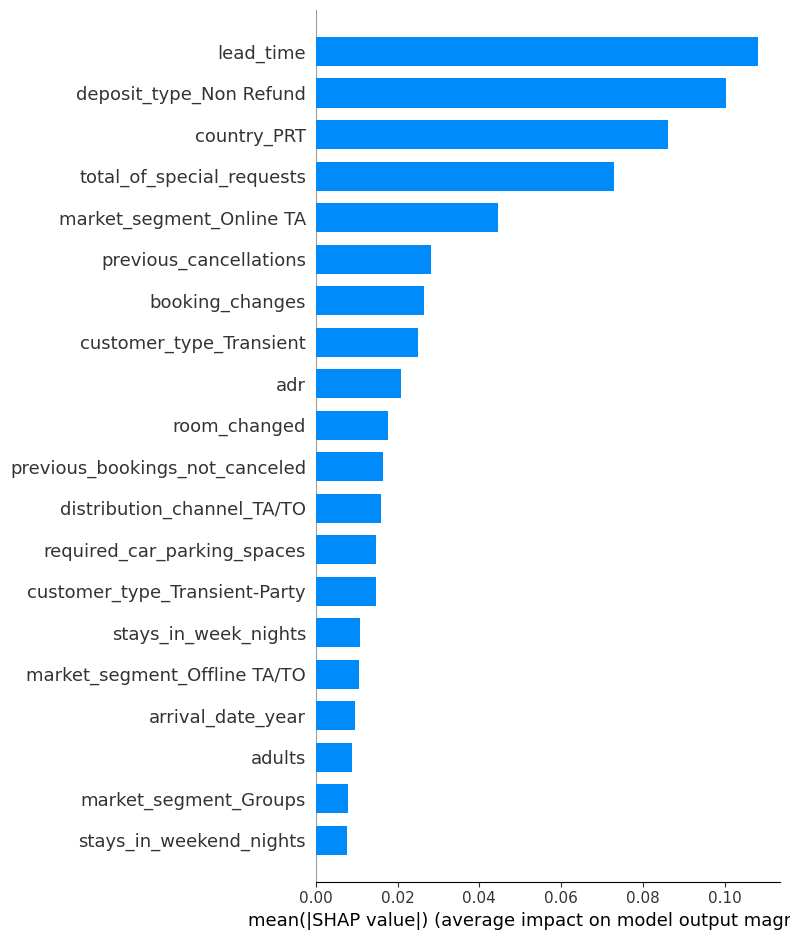

In [55]:
shap.summary_plot(
    shap_values_small_class1,
    X_shap_small,
    plot_type="bar"
)

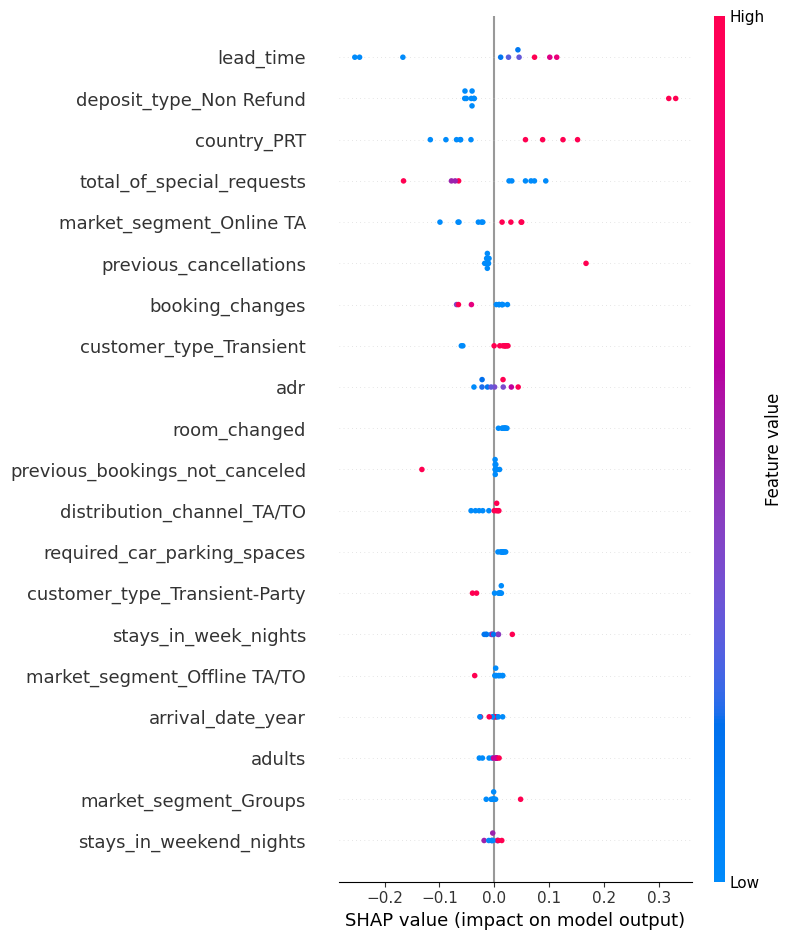

In [56]:
shap.summary_plot(
    shap_values_small_class1,
    X_shap_small
)

El análisis SHAP global, aunque realizado sobre una muestra reducida para evitar altos costes computacionales, muestra resultados consistentes con los análisis anteriores. Las variables con mayor impacto medio en la predicción son lead_time, deposit_type_Non Refund , country_PRT, total_of_special_requests y market_segment_Online TA. El summary plot permite además observar no solo la importancia de las variables, sino también la dirección de su efecto: por ejemplo, valores altos de lead_time tienden a aumentar la probabilidad de cancelación, mientras que valores altos de total_of_special_requests tienden a reducirla. En conjunto, este análisis confirma los patrones detectados previamente y proporciona una visión más detallada del comportamiento del modelo

# 7. Interpretación de resultados

A lo largo del trabajo se ha desarrollado un proceso completo de análisis predictivo para la cancelación de reservas hoteleras, comenzando con un análisis exploratorio que permitió depurar los datos y detectar que la cancelación responde a patrones concretos del comportamiento del cliente y de la reserva. Posteriormente, se compararon distintos modelos de clasificación, seleccionando Random Forest como el mejor por su equilibrio entre rendimiento e interpretabilidad.

El modelo alcanza una accuracy de 0.8906, con 13.734 verdaderos negativos, 7.260 verdaderos positivos, 1.033 falsos positivos y 1.546 falsos negativos, mostrando mejor capacidad para identificar no cancelaciones que cancelaciones. Las métricas (precision 0.8754, recall 0.8244, F1 0.8492 y AUC 0.9559) confirman una excelente capacidad predictiva. Desde el punto de vista de negocio, esto permite anticipar cancelaciones con fiabilidad y pasar de una gestión reactiva a una preventiva.

En cuanto a la explicabilidad, los análisis globales (feature importance y permutation importance) identifican como variables clave lead_time, total_of_special_requests, country_PRT y deposit_type_Non Refund. Los PDP muestran que una mayor antelación aumenta la probabilidad de cancelación, mientras que un mayor número de peticiones especiales la reduce, reflejando el nivel de compromiso del cliente. A nivel local, SHAP permite explicar casos individuales, mostrando cómo variables como lead_time o el canal de reserva impulsan el riesgo de cancelación. En conjunto, todos los análisis coinciden en que la cancelación está asociada a la antelación de la reserva, el compromiso del cliente y las condiciones de la misma, aportando no solo capacidad predictiva sino también una comprensión útil para la toma de decisiones.

# 8. Mejoras en políticas de cancelación

Los resultados obtenidos no deben entenderse únicamente como un ejercicio técnico, sino como una herramienta clave para la toma de decisiones en la gestión hotelera. La capacidad de anticipar cancelaciones permite al hotel actuar de forma preventiva, reduciendo tanto el impacto económico como la incertidumbre operativa. En este sentido, el modelo puede utilizarse como un sistema de alerta temprana para identificar reservas con mayor riesgo y aplicar medidas específicas antes de que se produzca la cancelación.

Una de las principales aplicaciones es la segmentación de reservas según su nivel de riesgo. Las reservas de bajo riesgo pueden seguir el proceso habitual, mientras que las de alto riesgo pueden gestionarse de forma más activa mediante recordatorios, confirmaciones adicionales o comunicaciones personalizadas orientadas a reforzar el compromiso del cliente. Asimismo, el tipo de depósito y las condiciones de cancelación pueden adaptarse según el riesgo estimado, aplicando políticas más flexibles o incentivando opciones no reembolsables, siempre evitando medidas excesivamente restrictivas que puedan perjudicar la experiencia del cliente.

El análisis de variables clave aporta además líneas de actuación concretas. Por ejemplo, el alto impacto de lead_time indica que las reservas realizadas con mucha antelación son más inestables, lo que sugiere la necesidad de realizar un seguimiento más activo de este tipo de clientes. Por otro lado, el efecto de total_of_special_requests muestra que un mayor nivel de implicación reduce la probabilidad de cancelación, lo que abre la puerta a estrategias de engagement basadas en la personalización de la experiencia. Además, el canal de reserva (market_segment_Online TA) revela que el comportamiento varía según el origen de la reserva, lo que permite adaptar la estrategia comercial y de comunicación a cada canal.

En cuanto a variables como el país de origen, es fundamental hacer un uso responsable. Aunque el modelo detecte diferencias de comportamiento entre mercados, estas no deben utilizarse para discriminar clientes individualmente, sino únicamente para análisis agregados, planificación de demanda o diseño de campañas específicas por mercado, garantizando siempre un enfoque ético y no discriminatorio.

En términos generales, el modelo debe utilizarse como una herramienta de apoyo a la decisión y no como un sistema automático. La clave no es penalizar reservas de alto riesgo, sino gestionarlas mejor mediante protocolos diferenciados. Además, la capacidad de anticipar cancelaciones permite mejorar la planificación de ocupación, ajustar estrategias de precios y optimizar el revenue management, impactando directamente en ingresos y eficiencia operativa.

Finalmente, como línea futura, sería recomendable monitorizar el modelo de forma continua y evaluar su rendimiento en términos de coste de negocio, ya que no todos los errores tienen el mismo impacto. En conclusión, el principal valor del modelo radica en transformar la predicción en acción: segmentar reservas, mejorar la comunicación, personalizar la experiencia y optimizar la gestión hotelera, siempre bajo un enfoque responsable y centrado en el cliente.